# Bacterial versus viral infection in children: what host blood gene expression can and cannot tell us

**Group Nine · Computing for Bioinformatics (ICS 4301) · Strathmore University · November 2026**

| Member | Student no. | Stage led (from the 4 Nov 2026 minutes) |
|---|---|---|
| Kelvin Murega | 166914 | 1. Research question, objectives, hypothesis, lecturer approval |
| Deborah Rehana | 168656 | 2. Data acquisition, documentation, cross-platform feature mapping |
| Andrew Karanja | 167144 | 3–4. Preprocessing, quality control, exploratory data analysis |
| Jeremy Kang'ethe | 166263 | 5. Differential expression with FDR correction |
| Eric Lenina | 161492 | 6. Biological interpretation (GO / pathway enrichment, literature) |
| Eric Muthii | 166390 | 7. Machine learning, independent validation, limitations |
| All members | | 8. Review of notebook, code and conclusions |

**How to run.** Open in Google Colab and choose *Runtime → Run all*. The notebook downloads everything it needs from
NCBI GEO and three pinned GitHub files, uses only packages that ship with Colab, and takes roughly 3–5 minutes on a
CPU runtime. Every random step uses a fixed seed, so a re-run reproduces the saved outputs.

## 1. Research question, objectives and hypothesis

**Research question.** Which blood genes and pathways differ between children with confirmed bacterial and confirmed
viral infections, and can these differences classify infection type in an independent dataset?

**Why it matters.** Febrile children are often given antibiotics because bacterial and viral infections look alike at
the bedside and cultures are slow. The child's own immune response (the *host* response) is measured in blood within
hours, so a reliable host signature could reduce unnecessary antibiotics without missing bacterial disease.

**Objectives**
1. Quality-check and explore the data.
2. Identify differentially expressed genes and pathways.
3. Compare a classifier with a baseline.
4. Test performance on an independent dataset and explain limitations.

*(Objectives as worded in the group's 4 November 2026 minutes. For objective 3 the group trains two comparison
models, logistic regression and random forest, against a majority-class baseline.)*

**Hypotheses**
* *H0 (Objective 2):* no gene differs in mean expression between bacterial and viral infection after false discovery
  rate (FDR) correction.
* *H1 (Objective 2):* viral infection raises interferon-stimulated genes, and bacterial infection raises neutrophil
  and inflammatory genes.
* *H1 (Objectives 3–4):* a classifier trained on GSE72809 beats the majority baseline on GSE42026, with a
  bootstrap 95% confidence interval for AUROC that excludes 0.5.

**Scope and approval.** The question and objectives are those agreed at the group's 4 November 2026 meeting and
submitted for lecturer approval before analysis, as the brief requires. This is a research analysis of public data. It
is **not** a diagnostic tool and must not be used to make treatment decisions for any child.

In [1]:
import gzip
import hashlib
import json
import shutil
import urllib.request
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.special import digamma, polygamma
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 9
BASE = Path.cwd()
RAW, RES, FIG = BASE / "data" / "raw", BASE / "results", BASE / "figures"
for d in (RAW, RES, FIG):
    d.mkdir(parents=True, exist_ok=True)

# Colours: bacterial = warm orange, viral = blue (validated for colour-vision deficiency, ΔE ≥ 17).
COL = {"Bacterial": "#D9622B", "Viral": "#1A7FA8"}
INK, MUTED, GRID = "#2B2B2B", "#6B6B6B", "#E4E4E4"
DIVERGING = LinearSegmentedColormap.from_list("bv", [COL["Viral"], "#F2F2F2", COL["Bacterial"]])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "legend.frameon": False, "figure.facecolor": "white",
})


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()


def annotate_nonoverlap(ax, xs, ys, labels, fontsize=7.5, gap_px=11):
    """Label points, nudging labels upward when they would collide (call after axis limits are final)."""
    ax.figure.canvas.draw()
    pts = ax.transData.transform(np.column_stack([xs, ys]))
    placed = []
    for i in np.argsort(pts[:, 1]):
        x, y = pts[i]
        ty = y
        while any(abs(px - x) < 70 and abs(py - ty) < gap_px for px, py in placed):
            ty += gap_px
        placed.append((x, ty))
        dy = (ty - y) * 72 / ax.figure.dpi
        ax.annotate(labels[i], (xs[i], ys[i]), xytext=(4, 2 + dy), textcoords="offset points", fontsize=fontsize,
                    color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.5) if dy > 3 else None)


print("python", ".".join(map(str, __import__("sys").version_info[:3])), "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| networkx", nx.__version__)

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | networkx 3.7


## 2. Data acquisition

| Role | GEO series | Platform | Cohort |
|---|---|---|---|
| Discovery: differential expression and model development | **GSE72809** | GPL10558, Illumina HumanHT-12 V4 | Febrile children under 17 with bacterial, viral or uncertain infection, and controls (Herberg *et al.*, JAMA 2016) |
| Independent test, never used for any fitting | **GSE42026** | GPL6947, Illumina HumanHT-12 V3 | Children hospitalised with H1N1/09 influenza, RSV or bacterial infection, and healthy controls (Herberg *et al.*, J Infect Dis 2013) |

Both are whole-blood microarray studies. The series-matrix files hold the submitters' processed expression values and
the sample metadata. Illumina probe IDs are shared across the V3 and V4 chips when the probe sequence is identical,
so we match the two datasets **probe by probe** rather than by gene name.

Two supporting files come from pinned GitHub commits (checked with SHA-256):
* a probe → gene table exported from Bioconductor's `illuminaHumanv4.db` 1.26.0 (MIT-licensed export);
* the gene-set libraries used for enrichment: Enrichr *GO Biological Process 2021* and MSigDB *Hallmark* v7.0
  (as distributed in the GSEApy test data).

In [2]:
SOURCES = {
    "GSE72809": dict(
        url="https://ftp.ncbi.nlm.nih.gov/geo/series/GSE72nnn/GSE72809/matrix/GSE72809_series_matrix.txt.gz",
        role="discovery", platform="GPL10558 (HumanHT-12 V4)"),
    "GSE42026": dict(
        url="https://ftp.ncbi.nlm.nih.gov/geo/series/GSE42nnn/GSE42026/matrix/GSE42026_series_matrix.txt.gz",
        role="independent test", platform="GPL6947 (HumanHT-12 V3)"),
}
PINNED = {
    "illuminaHumanv4_probe_annotation.tsv": dict(
        url=("https://raw.githubusercontent.com/rmaghembe1/host-response-module-transportability/"
             "5acd5d5d160d72174ffcb5e91af94ccfdf2e3c91/results/external_projection_candidate_audit/"
             "GSE73461_identifier_coverage/GSE73461_illuminaHumanv4_probe_annotation_join.tsv"),
        sha256="fdd8a706aeb74030c28d5eeb6d8050e92d11f95807b4d72919b23652c21de850"),
    "GO_Biological_Process_2021.gmt": dict(
        url=("https://raw.githubusercontent.com/zqfang/GSEApy/fedb6015200adc21ed06cb2ca143ca272373a240/"
             "tests/extdata/enrichr.GO_Biological_Process_2021.gmt"),
        sha256="5987ce789053fdd5533393cd65b9abdb5e08e4fade7b0625a1fe234a1207eea4"),
    "MSigDB_Hallmark_v7.0.gmt": dict(
        url=("https://raw.githubusercontent.com/zqfang/GSEApy/fedb6015200adc21ed06cb2ca143ca272373a240/"
             "tests/extdata/h.all.v7.0.symbols.gmt"),
        sha256="4803c09aae50bbd96d53fc681bd5545a4c89278993c15145dd7b7c994f893516"),
}


def fetch(url, dest, sha256=None):
    """Download url to dest unless it is already there; verify the checksum when one is given."""
    dest = Path(dest)
    if not dest.exists():
        print("downloading", url)
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (Group9 notebook)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(dest, "wb") as fh:
            shutil.copyfileobj(r, fh)
    digest = hashlib.sha256(dest.read_bytes()).hexdigest()
    if sha256 and digest != sha256:
        raise ValueError(f"checksum mismatch for {dest.name}")
    return dest, digest


files = {}
for gse, s in SOURCES.items():
    files[gse] = fetch(s["url"], RAW / Path(s["url"]).name)
for name, s in PINNED.items():
    files[name] = fetch(s["url"], RAW / name, s["sha256"])
for k, (p, h) in files.items():
    print(f"{p.name:48s} {p.stat().st_size / 1e6:7.2f} MB  sha256 {h[:16]}…")

GSE72809_series_matrix.txt.gz                      73.32 MB  sha256 75ec0126705c2e9e…
GSE42026_series_matrix.txt.gz                      19.36 MB  sha256 9a6674a066fbb517…
illuminaHumanv4_probe_annotation.tsv                2.85 MB  sha256 fdd8a706aeb74030…
GO_Biological_Process_2021.gmt                      1.53 MB  sha256 5987ce789053fdd5…
MSigDB_Hallmark_v7.0.gmt                            0.05 MB  sha256 4803c09aae50bbd9…


In [3]:
def read_series_matrix(path):
    """Parse a GEO series-matrix file into (series header, sample metadata, probe x sample expression)."""
    series, fields, begin, end = {}, [], None, None
    with gzip.open(path, "rt", encoding="utf-8", errors="replace") as fh:
        for i, line in enumerate(fh):
            if line.startswith("!series_matrix_table_begin"):
                begin = i
                continue
            if line.startswith("!series_matrix_table_end"):
                end = i
                break
            if begin is not None:
                continue
            parts = line.rstrip("\n").split("\t")
            key, vals = parts[0], [v.strip().strip('"') for v in parts[1:]]
            if key.startswith("!Series_"):
                series.setdefault(key[8:], []).append(" ".join(vals))
            elif key.startswith("!Sample_"):
                fields.append((key[8:], vals))
    expr = pd.read_csv(path, sep="\t", skiprows=begin + 1, nrows=end - begin - 2, index_col=0,
                       compression="gzip", na_values=["null", "NA", "NaN", ""])
    expr.index = expr.index.astype(str).str.strip('"')
    expr.columns = [str(c).strip('"') for c in expr.columns]
    gsm = next(v for k, v in fields if k == "geo_accession")
    rows, seen = {g: {} for g in gsm}, {}
    for key, vals in fields:
        if key.startswith("characteristics"):
            for g, v in zip(gsm, vals):
                if v:
                    k, sep, val = v.partition(":")
                    rows[g][(k if sep else key).strip().lower()] = val.strip() if sep else v.strip()
        else:
            seen[key] = seen.get(key, 0) + 1
            col = key if seen[key] == 1 else f"{key}_{seen[key]}"
            for g, v in zip(gsm, vals):
                rows[g][col] = v
    meta = pd.DataFrame.from_dict(rows, orient="index")
    return series, meta.loc[expr.columns], expr.astype("float64")


data = {}
for gse in SOURCES:
    series, meta, expr = read_series_matrix(files[gse][0])
    data[gse] = dict(series=series, meta=meta, expr=expr)
    print(f"{gse}: {series['title'][0][:95]}")
    print(f"   {expr.shape[0]:,} probes x {expr.shape[1]} samples | platform {series.get('platform_id', ['?'])[0]}"
          f" | PubMed {series.get('pubmed_id', ['-'])[0]}")

GSE72809: Diagnosis of childhood bacterial and viral infection using host RNA expression [Discovery set]
   47,323 probes x 292 samples | platform GPL10558 | PubMed 27552617


GSE42026: Transcriptomic profiling in childhood H1N1/09 influenza reveals reduced expression of protein s
   48,803 probes x 92 samples | platform GPL6947 | PubMed 23901082


### 2.1 Description of every file and variable

In [4]:
file_table = pd.DataFrame([
    dict(file=files[g][0].name, source=f"NCBI GEO {g}", role=s["role"], platform=s["platform"],
         size_MB=round(files[g][0].stat().st_size / 1e6, 2), contents="series header, sample metadata, "
         f"{data[g]['expr'].shape[0]:,} probes x {data[g]['expr'].shape[1]} samples (processed expression)")
    for g, s in SOURCES.items()] + [
    dict(file="illuminaHumanv4_probe_annotation.tsv", source="Bioconductor illuminaHumanv4.db 1.26.0 (pinned export)",
         role="probe to gene mapping", platform="HumanHT-12 V4 probe IDs",
         size_MB=round(files["illuminaHumanv4_probe_annotation.tsv"][0].stat().st_size / 1e6, 2),
         contents="ID_REF (Illumina probe ID), ARRAY_ID, SYMBOL (HGNC symbol), ENTREZID, ENSEMBL, SYMBOL_UPPER"),
    dict(file="GO_Biological_Process_2021.gmt", source="Enrichr library via GSEApy (pinned)", role="enrichment",
         platform="gene symbols", size_MB=round(files["GO_Biological_Process_2021.gmt"][0].stat().st_size / 1e6, 2),
         contents="one GO biological-process term per line followed by its member genes"),
    dict(file="MSigDB_Hallmark_v7.0.gmt", source="MSigDB via GSEApy (pinned)", role="enrichment",
         platform="gene symbols", size_MB=round(files["MSigDB_Hallmark_v7.0.gmt"][0].stat().st_size / 1e6, 2),
         contents="50 hallmark gene sets, one per line"),
])
display(file_table)

GEO_FIELDS = {
    "title": "submitter's sample name", "geo_accession": "GEO sample ID (GSM), unique per array",
    "status": "public release date", "submission_date": "date submitted to GEO",
    "last_update_date": "date of last GEO update", "type": "molecule type", "channel_count": "number of dye channels",
    "source_name_ch1": "biological source", "organism_ch1": "species", "molecule_ch1": "extracted molecule",
    "extract_protocol_ch1": "RNA extraction protocol", "label_ch1": "label used", "label_protocol_ch1": "labelling protocol",
    "taxid_ch1": "NCBI taxonomy ID", "hyb_protocol": "hybridisation protocol", "scan_protocol": "scanning protocol",
    "description": "free-text sample description", "data_processing": "how expression values were processed",
    "platform_id": "GEO platform (array type)", "contact_name": "submitter", "supplementary_file": "raw-data file link",
    "data_row_count": "number of probes reported for the sample",
}


def variable_table(meta, gse):
    rows = []
    for c in meta.columns:
        vals = meta[c].astype(str)
        desc = GEO_FIELDS.get(c, GEO_FIELDS.get(c.split("_")[0], ""))
        if not desc:
            desc = "clinical characteristic" if not c[0].isupper() and "_" not in c[:3] else "GEO administrative field"
        rows.append(dict(dataset=gse, variable=c, description=desc, n_unique=vals.nunique(),
                         example=vals.value_counts().index[0][:70]))
    return pd.DataFrame(rows)


var_tables = pd.concat([variable_table(data[g]["meta"], g) for g in SOURCES], ignore_index=True)
var_tables.to_csv(RES / "variable_dictionary.csv", index=False)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(var_tables)

,file,source,role,platform,size_MB,contents
0,GSE72809_series_matrix.txt.gz,NCBI GEO GSE72809,discovery,GPL10558 (HumanHT-12 V4),73.32,"series header, sample metadata, 47,323 probes ..."
1,GSE42026_series_matrix.txt.gz,NCBI GEO GSE42026,independent test,GPL6947 (HumanHT-12 V3),19.36,"series header, sample metadata, 48,803 probes ..."
2,illuminaHumanv4_probe_annotation.tsv,Bioconductor illuminaHumanv4.db 1.26.0 (pinned...,probe to gene mapping,HumanHT-12 V4 probe IDs,2.85,"ID_REF (Illumina probe ID), ARRAY_ID, SYMBOL (..."
3,GO_Biological_Process_2021.gmt,Enrichr library via GSEApy (pinned),enrichment,gene symbols,1.53,one GO biological-process term per line follow...
4,MSigDB_Hallmark_v7.0.gmt,MSigDB via GSEApy (pinned),enrichment,gene symbols,0.05,"50 hallmark gene sets, one per line"


,dataset,variable,description,n_unique,example
0,GSE72809,title,submitter's sample name,292,Definite Bacterial_01
1,GSE72809,geo_accession,"GEO sample ID (GSM), unique per array",292,GSM1872417
2,GSE72809,status,public release date,1,Public on Aug 29 2016
3,GSE72809,submission_date,date submitted to GEO,2,Sep 08 2015
4,GSE72809,last_update_date,date of last GEO update,1,Aug 29 2016
5,GSE72809,type,molecule type,1,RNA
6,GSE72809,channel_count,number of dye channels,1,1
7,GSE72809,source_name_ch1,biological source,6,Whole Blood from patient with Definite Viral infection
8,GSE72809,organism_ch1,species,1,Homo sapiens
9,GSE72809,category,clinical characteristic,6,Definite Viral


**Interpretation.** Both files loaded with the expected structure: GSE72809 has 292 arrays × 47,323 probes and
GSE42026 has 92 arrays × 48,803 probes. GSE72809 holds 52 definite bacterial and 92 definite viral cases, and
GSE42026 holds 18 bacterial and 41 viral cases (19 H1N1/09, 22 RSV). Both match the design counts in our minutes.
The metadata give infection category and sex for every child, but **no age**, so age cannot be checked or adjusted
for. The two series were also processed differently by their submitters. GSE72809 was normalised with robust spline
normalisation (RSN) in R, and GSE42026 with GenomeStudio background subtraction and quantile normalisation. That
difference is the first reason the datasets cannot simply be pooled.

## 3. Preprocessing and quality control

### 3.1 Choose the samples that answer the question
The primary analysis is a clean two-class comparison, so only **definite** bacterial and **definite** viral cases are
kept. Healthy controls, probable, indeterminate and uncertain cases are excluded, as agreed in the minutes. The raw
label fields are printed first so the mapping can be checked.

In [5]:
LABEL_RULES = {}  # filled in the next cell once the label fields are known


def show_label_fields(meta, max_unique=25):
    for c in meta.columns:
        vc = meta[c].value_counts(dropna=False)
        if 1 < len(vc) <= max_unique and c not in ("status", "submission_date", "last_update_date"):
            print(f"--- {c}")
            print(vc.to_string())


for gse in SOURCES:
    print(f"\n==================== {gse}")
    show_label_fields(data[gse]["meta"])


==================== GSE72809
--- source_name_ch1
source_name_ch1
Whole Blood from patient with Definite Viral infection                               92
Whole Blood from patient with Definite Bacterial infection                           52
Whole Blood from healthy control                                                     52
Whole Blood from patient with infection of uncertain bacterial or viral aetiology    49
Whole Blood from patient with Probable Bacterial infection                           42
Whole Blood from patient with Probable Viral infection                                5
--- category
category
Definite Viral        92
Definite Bacterial    52
Control               52
Uncertain             49
Probable Bacterial    42
Probable Viral         5
--- gender
gender
Male      176
Female    116
--- tissue
tissue
Whole Blood    240
whole blood     52
--- data_processing_2
data_processing_2
The software used for data normalization was 'R' Language and Environment for Statistical C

In [6]:
def rules_72809(meta):
    cat = meta["category"].str.strip()
    group = cat.map({"Definite Bacterial": "Bacterial", "Definite Viral": "Viral"}).fillna("excluded")
    return pd.DataFrame({"group": group, "subtype": cat,
                         "sex_recorded": meta["gender"].str.strip().str.lower()}, index=meta.index)


def rules_42026(meta):
    p = meta["infecting pathogen"].str.strip()
    group = p.map({"gram positive bacterial infection": "Bacterial", "Influenza A H1N1/09": "Viral",
                   "RSV": "Viral"}).fillna("excluded")
    sub = p.map({"gram positive bacterial infection": "Gram-positive bacterial", "Influenza A H1N1/09": "H1N1/09 influenza",
                 "RSV": "RSV", "none": "Healthy control"})
    return pd.DataFrame({"group": group, "subtype": sub,
                         "sex_recorded": meta["gender"].str.strip().str.lower()}, index=meta.index)


LABEL_RULES = {"GSE72809": rules_72809, "GSE42026": rules_42026}

# Suspicious-value check before selection: are all arrays in a series on the same scale?
for gse, col in [("GSE72809", "category"), ("GSE42026", "infecting pathogen")]:
    m, X = data[gse]["meta"], data[gse]["expr"]
    print(f"{gse}: largest value per array, by group")
    display(X.max().groupby(m[col]).agg(["min", "max"]).round(1))

GSE72809: largest value per array, by group


,min,max
category,,
Control,50464.2,67444.2
Definite Bacterial,15.1,16.3
Definite Viral,15.2,16.5
Probable Bacterial,15.1,16.4
Probable Viral,15.7,16.3
Uncertain,15.3,16.6


GSE42026: largest value per array, by group


,min,max
infecting pathogen,,
Influenza A H1N1/09,34376.6,34376.6
RSV,34376.6,34376.6
gram positive bacterial infection,34376.6,34376.6
none,34376.6,34376.6


In [7]:
counts = []  # before/after log


def record(gse, step, n_samples, n_features, note=""):
    counts.append(dict(dataset=gse, step=step, samples=n_samples, features=n_features, note=note))


for gse in SOURCES:
    d = data[gse]
    record(gse, "1 downloaded", d["expr"].shape[1], d["expr"].shape[0], "all arrays in the series")
    d["meta"] = d["meta"].join(LABEL_RULES[gse](d["meta"]))
    print(gse, "label mapping:\n", d["meta"].groupby(["group", "subtype"], dropna=False).size().to_string(), "\n")
    keep = d["meta"]["group"].isin(["Bacterial", "Viral"])
    d["meta"], d["expr"] = d["meta"].loc[keep].copy(), d["expr"].loc[:, keep]
    record(gse, "2 definite bacterial / viral only", keep.sum(), d["expr"].shape[0],
           f"excluded {int((~keep).sum())} control / probable / uncertain arrays")

GSE72809 label mapping:
 group      subtype           
Bacterial  Definite Bacterial    52
Viral      Definite Viral        92
excluded   Control               52
           Probable Bacterial    42
           Probable Viral         5
           Uncertain             49 

GSE42026 label mapping:
 group      subtype                
Bacterial  Gram-positive bacterial    18
Viral      H1N1/09 influenza          19
           RSV                        22
excluded   Healthy control            33 



### 3.2 Value scale, missing values and normalisation
We check whether the deposited values are already log2-transformed and normalised before transforming anything.
Transforming already-logged data twice is a common silent error.

In [8]:
def scale_report(X, name):
    q = X.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    med_sd = q.loc[0.5].std()
    return dict(dataset=name, min=round(np.nanmin(X.values), 3), max=round(np.nanmax(X.values), 3),
                median=round(np.nanmedian(X.values), 3), missing=int(X.isna().sum().sum()),
                sd_of_sample_medians=round(med_sd, 4), sd_of_sample_IQRs=round((q.loc[0.75] - q.loc[0.25]).std(), 4))


def quantile_normalize(X):
    order = np.argsort(X.values, axis=0)
    ref = np.sort(X.values, axis=0).mean(axis=1)
    out = np.empty_like(X.values)
    for j in range(X.shape[1]):
        out[order[:, j], j] = ref
    return pd.DataFrame(out, index=X.index, columns=X.columns)


pre_norm = {}
scale_rows = []
for gse in SOURCES:
    d = data[gse]
    X = d["expr"]
    scale_rows.append(scale_report(X, f"{gse} as deposited"))
    n_na = X.isna().any(axis=1).sum()
    X = X.dropna()
    record(gse, "3 probes with no missing values", X.shape[1], X.shape[0], f"dropped {n_na} probes with missing values")
    if np.nanmax(X.values) > 100:  # intensities on the raw scale
        X = np.log2(X.clip(lower=1))
        print(f"{gse}: values were on the raw intensity scale -> log2 transformed")
    else:
        print(f"{gse}: values already on a log2 scale -> not transformed again")
    pre_norm[gse] = X.copy()
    if scale_report(X, gse)["sd_of_sample_medians"] > 0.05:
        X = quantile_normalize(X)
        print(f"{gse}: sample distributions differed -> quantile normalised")
    else:
        print(f"{gse}: sample distributions already aligned -> left as deposited")
    d["expr"] = X
    scale_rows.append(scale_report(X, f"{gse} after preprocessing"))
display(pd.DataFrame(scale_rows))

GSE72809: values already on a log2 scale -> not transformed again


GSE72809: sample distributions already aligned -> left as deposited


GSE42026: values were on the raw intensity scale -> log2 transformed
GSE42026: sample distributions already aligned -> left as deposited


,dataset,min,max,median,missing,sd_of_sample_medians,sd_of_sample_IQRs
0,GSE72809 as deposited,-4.292,16.499,5.496,0,0.0072,0.0368
1,GSE72809 after preprocessing,-4.292,16.499,5.496,0,0.0072,0.0368
2,GSE42026 as deposited,-20.938,34376.610,5.485,0,0.0111,0.0362
3,GSE42026 after preprocessing,0.000,15.069,2.455,0,0.0029,0.0021


### 3.3 Biology that must hold: blood markers and sex genes
Whole blood is dominated by red-cell and immune transcripts, so haemoglobin and immune housekeeping genes should sit
at the top of the expression range. Sex is a built-in label check: females express *XIST* and lack Y-chromosome genes
(*RPS4Y1, DDX3Y, KDM5D, EIF1AY*); males show the reverse. A sample whose expression disagrees with its recorded sex
may be mislabelled.

In [9]:
ann = pd.read_csv(files["illuminaHumanv4_probe_annotation.tsv"][0], sep="\t", dtype=str)
ann = ann.dropna(subset=["SYMBOL"])
n_sym = ann.groupby("ID_REF")["SYMBOL"].nunique()
probe2sym = ann[ann["ID_REF"].isin(n_sym[n_sym == 1].index)].drop_duplicates("ID_REF").set_index("ID_REF")["SYMBOL"]
print(f"annotation: {ann['ID_REF'].nunique():,} annotated probes; {len(probe2sym):,} map to exactly one gene "
      f"({int((n_sym > 1).sum()):,} ambiguous probes set aside)")


def gene_probe_values(X, gene):
    ids = [p for p in probe2sym.index[probe2sym == gene] if p in X.index]
    if not ids:
        return None
    best = X.loc[ids].mean(axis=1).idxmax()
    return X.loc[best]


def percentile_of(X, gene):
    v = gene_probe_values(X, gene)
    if v is None:
        return np.nan
    return round(stats.percentileofscore(X.mean(axis=1), v.mean()), 1)


marker_rows = []
for gse in SOURCES:
    X = data[gse]["expr"]
    for g in ["HBB", "HBA2", "ACTB", "B2M", "GAPDH", "CD3E", "CD14", "ALB", "INS"]:
        marker_rows.append(dict(dataset=gse, gene=g, percentile_of_mean_expression=percentile_of(X, g)))
markers = pd.DataFrame(marker_rows).pivot(index="gene", columns="dataset", values="percentile_of_mean_expression")
markers["expected"] = markers.index.map({"HBB": "high (red cells)", "HBA2": "high (red cells)",
                                          "ACTB": "high (housekeeping)", "B2M": "high (housekeeping)",
                                          "GAPDH": "high (housekeeping)", "CD3E": "high (T cells)",
                                          "CD14": "high (monocytes)", "ALB": "low (liver only)",
                                          "INS": "low (pancreas only)"})
markers = markers.sort_values("expected")
display(markers)

annotation: 35,689 annotated probes; 33,984 map to exactly one gene (1,705 ambiguous probes set aside)


dataset,GSE42026,GSE72809,expected
gene,,,
CD3E,94.9,91.0,high (T cells)
ACTB,100.0,99.9,high (housekeeping)
B2M,99.8,99.8,high (housekeeping)
GAPDH,99.5,99.3,high (housekeeping)
CD14,99.8,99.7,high (monocytes)
HBA2,100.0,100.0,high (red cells)
HBB,100.0,100.0,high (red cells)
ALB,52.9,69.9,low (liver only)
INS,56.1,65.8,low (pancreas only)


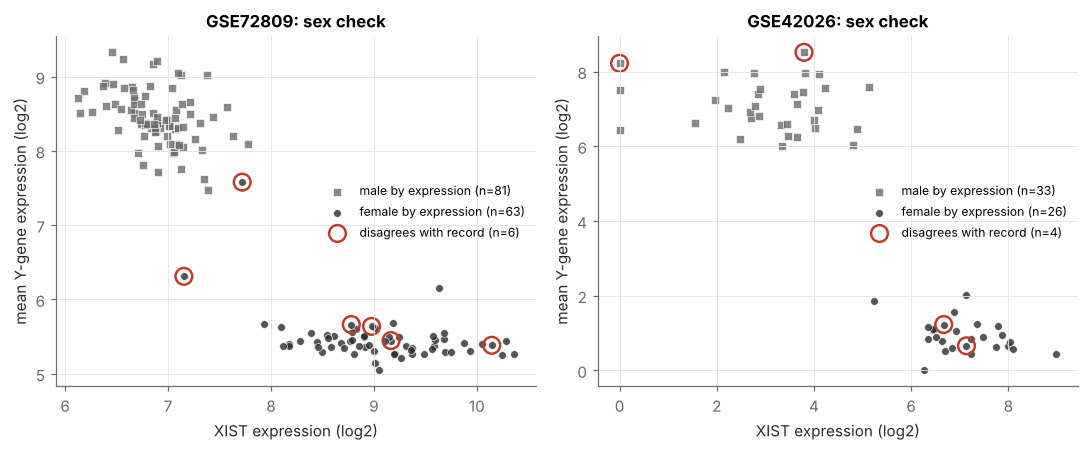

GSE72809: recorded sex agrees with expression for 138/144 samples
GSE42026: recorded sex agrees with expression for 55/59 samples


In [10]:
Y_GENES = ["RPS4Y1", "DDX3Y", "KDM5D", "EIF1AY"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
sex_checks = {}
for ax, gse in zip(axes, SOURCES):
    d = data[gse]
    X = d["expr"]
    xist = gene_probe_values(X, "XIST")
    ysc = pd.concat([gene_probe_values(X, g) for g in Y_GENES if gene_probe_values(X, g) is not None], axis=1).mean(axis=1)
    pred = np.where(ysc - xist > 0, "male", "female")
    rec = d["meta"].get("sex_recorded")
    chk = pd.DataFrame({"XIST": xist, "Y_score": ysc, "sex_from_expression": pred,
                        "sex_recorded": rec if rec is not None else "not recorded"})
    sex_checks[gse] = chk
    for sx, mk in [("male", "s"), ("female", "o")]:
        m = chk["sex_from_expression"] == sx
        ax.scatter(chk.loc[m, "XIST"], chk.loc[m, "Y_score"], s=26, marker=mk, alpha=0.8,
                   color=MUTED if sx == "male" else INK, label=f"{sx} by expression (n={m.sum()})", edgecolor="white", lw=0.5)
    if rec is not None:
        bad = chk[(chk["sex_recorded"].isin(["male", "female"])) & (chk["sex_recorded"] != chk["sex_from_expression"])]
        ax.scatter(bad["XIST"], bad["Y_score"], s=120, facecolor="none", edgecolor="#C0392B", lw=1.6,
                   label=f"disagrees with record (n={len(bad)})")
    ax.set(title=f"{gse}: sex check", xlabel="XIST expression (log2)", ylabel="mean Y-gene expression (log2)")
    ax.legend(loc="center right", fontsize=8)
fig.tight_layout()
savefig(fig, "fig01_sex_check")
for gse, chk in sex_checks.items():
    if chk["sex_recorded"].iloc[0] != "not recorded":
        known = chk["sex_recorded"].isin(["male", "female"])
        agree = (chk.loc[known, "sex_recorded"] == chk.loc[known, "sex_from_expression"])
        print(f"{gse}: recorded sex agrees with expression for {agree.sum()}/{known.sum()} samples")
    else:
        print(f"{gse}: no recorded sex field; expression-inferred sex is reported only")

### 3.4 Outliers and duplicate arrays
Each array is compared with every other array of the same dataset, using the 5,000 most variable probes among the
expressed half (unexpressed probes near the floor are mostly noise). An array whose average correlation with the rest
is far below the others (more than 5 median absolute deviations) is flagged as a technical outlier. Pairs with
correlation above 0.995 are flagged as possible duplicate arrays of the same child.

In [11]:
outlier_flags = {}
for gse in SOURCES:
    X = data[gse]["expr"]
    on = X.loc[X.mean(axis=1) > X.mean(axis=1).median()]  # expressed half only: floor noise would dominate otherwise
    hv = on.loc[on.var(axis=1).sort_values(ascending=False).index[:5000]]
    C = np.corrcoef(hv.T.values)
    np.fill_diagonal(C, np.nan)
    mean_r = pd.Series(np.nanmean(C, axis=1), index=X.columns)
    mad = stats.median_abs_deviation(mean_r)
    flagged = mean_r[mean_r < mean_r.median() - 5 * mad]
    iu = np.triu_indices_from(C, 1)
    dup_pairs = [(X.columns[i], X.columns[j], round(C[i, j], 4)) for i, j in zip(*iu) if C[i, j] > 0.995]
    outlier_flags[gse] = dict(mean_r=mean_r, flagged=list(flagged.index), duplicates=dup_pairs)
    print(f"{gse}: mean inter-array r = {mean_r.median():.3f} (range {mean_r.min():.3f}–{mean_r.max():.3f}); "
          f"flagged outliers: {list(flagged.round(3).items()) or 'none'}; possible duplicates: {dup_pairs or 'none'}")

GSE72809: mean inter-array r = 0.838 (range 0.695–0.889); flagged outliers: [('GSM1872420', 0.736), ('GSM1872435', 0.695)]; possible duplicates: none
GSE42026: mean inter-array r = 0.517 (range 0.349–0.573); flagged outliers: [('GSM1030804', 0.349), ('GSM1030840', 0.393)]; possible duplicates: none


In [12]:
qc_flagged = {}
for gse in SOURCES:
    chk = sex_checks[gse]
    sex_bad = set(chk.index[chk["sex_recorded"].isin(["male", "female"]) & (chk["sex_recorded"] != chk["sex_from_expression"])])
    qc_flagged[gse] = sorted(sex_bad | set(outlier_flags[gse]["flagged"]))
    grp = data[gse]["meta"].loc[qc_flagged[gse], "group"].value_counts().to_dict()
    print(f"{gse}: {len(sex_bad)} sex-discordant + {len(outlier_flags[gse]['flagged'])} low-correlation arrays "
          f"-> {len(qc_flagged[gse])} flagged {grp}")
print("Decision: all arrays stay in the primary analysis, which matches the published cohort sizes. The flagged arrays")
print("are removed in sensitivity analyses (Sections 5 and 7.3) to show whether they change any conclusion.")

GSE72809: 6 sex-discordant + 2 low-correlation arrays -> 7 flagged {'Viral': 5, 'Bacterial': 2}
GSE42026: 4 sex-discordant + 2 low-correlation arrays -> 5 flagged {'Bacterial': 3, 'Viral': 2}
Decision: all arrays stay in the primary analysis, which matches the published cohort sizes. The flagged arrays
are removed in sensitivity analyses (Sections 5 and 7.3) to show whether they change any conclusion.


### 3.5 Remove unexpressed probes, annotate and collapse to one probe per gene
About half of the probes on a whole-blood array measure genes that are not expressed in blood. They add noise and
inflate the multiple-testing burden. A probe is kept if its value exceeds the dataset-wide median in at least as many
arrays as the smaller class (so a gene switched on in only one class is not lost). This filter never looks at the
labels. Each gene is then represented by its most highly expressed probe in the discovery data, and **the same probe
ID** is used in the test data, so both datasets measure the identical probe sequence.

In [13]:
gse_d, gse_t = "GSE72809", "GSE42026"
Xd = data[gse_d]["expr"]
n_min = data[gse_d]["meta"]["group"].value_counts().min()
thr = np.median(Xd.values)
expressed = (Xd > thr).sum(axis=1) >= n_min
Xd = Xd.loc[expressed]
record(gse_d, "5 expressed probes", Xd.shape[1], Xd.shape[0],
       f"value > {thr:.2f} (dataset median) in >= {n_min} arrays")
Xd = Xd.loc[Xd.index.isin(probe2sym.index)]
record(gse_d, "6 probes mapped to one gene", Xd.shape[1], Xd.shape[0], "illuminaHumanv4.db, unambiguous probes")
rep_probe = Xd.mean(axis=1).groupby(probe2sym.reindex(Xd.index)).idxmax()  # gene -> representative probe
Gd = Xd.loc[rep_probe.values]
Gd.index = rep_probe.index
record(gse_d, "7 one probe per gene", Gd.shape[1], Gd.shape[0], "highest mean expression probe per gene")

Xt = data[gse_t]["expr"]
shared_probe = rep_probe[rep_probe.isin(Xt.index)]
record(gse_t, "5 discovery probes present on V3 chip", Xt.shape[1], len(shared_probe),
       f"{len(shared_probe)}/{len(rep_probe)} representative probes have the same ID on HumanHT-12 V3")
Gt = Xt.loc[shared_probe.values]
Gt.index = shared_probe.index
n_flat = int((Gt.std(axis=1) == 0).sum())
Gt = Gt.loc[Gt.std(axis=1) > 0]  # a probe at the floor in every test array cannot be tested or used
record(gse_t, "6 genes available for testing", Gt.shape[1], Gt.shape[0],
       f"same probe sequence as discovery; {n_flat} probes constant at the floor dropped")

yd = (data[gse_d]["meta"]["group"] == "Bacterial").astype(int).values
yt = (data[gse_t]["meta"]["group"] == "Bacterial").astype(int).values
count_table = pd.DataFrame(counts)
count_table.to_csv(RES / "preprocessing_counts.csv", index=False)
display(count_table)
print(f"Final discovery matrix: {Gd.shape[0]:,} genes x {Gd.shape[1]} children ({yd.sum()} bacterial, {(1 - yd).sum()} viral)")
print(f"Final test matrix:      {Gt.shape[0]:,} genes x {Gt.shape[1]} children ({yt.sum()} bacterial, {(1 - yt).sum()} viral)")

,dataset,step,samples,features,note
0,GSE72809,1 downloaded,292,47323,all arrays in the series
1,GSE72809,2 definite bacterial / viral only,144,47323,excluded 148 control / probable / uncertain ar...
2,GSE42026,1 downloaded,92,48803,all arrays in the series
3,GSE42026,2 definite bacterial / viral only,59,48803,excluded 33 control / probable / uncertain arrays
4,GSE72809,3 probes with no missing values,144,47323,dropped 0 probes with missing values
5,GSE42026,3 probes with no missing values,59,48803,dropped 0 probes with missing values
6,GSE72809,5 expressed probes,144,25271,value > 5.50 (dataset median) in >= 52 arrays
7,GSE72809,6 probes mapped to one gene,144,19701,"illuminaHumanv4.db, unambiguous probes"
8,GSE72809,7 one probe per gene,144,13701,highest mean expression probe per gene
9,GSE42026,5 discovery probes present on V3 chip,59,12544,12544/13701 representative probes have the sam...


Final discovery matrix: 13,701 genes x 144 children (52 bacterial, 92 viral)
Final test matrix:      12,543 genes x 59 children (18 bacterial, 41 viral)


**Interpretation.**
* **Selection.** 148 GSE72809 arrays and 33 GSE42026 arrays were excluded (controls, probable and uncertain cases),
  leaving 144 discovery and 59 test children.
* **One suspicious finding.** The 52 healthy controls in GSE72809 are on the raw intensity scale (maximum
  ≈ 50,000–67,000), while every patient array is log2 (maximum ≈ 16). The controls were processed separately. Anyone
  who analysed all 292 arrays together would have compared two different scales. The controls are excluded from our
  question anyway.
* **Scale.** The GSE72809 patient arrays were already log2-transformed with aligned distributions (SD of sample
  medians 0.007), so they were left as deposited. GSE42026 was on the raw scale and about 25% of its values were zero
  or negative after background subtraction. Values below 1 were set to 1 (unexpressed) before log2. The resulting
  floor at 0 is why its distributions look truncated in Figure 2.
* **Known biology holds.** Haemoglobin genes (*HBB*, *HBA2*) sit at the 100th percentile of expression, and
  housekeeping genes (*ACTB*, *B2M*, *GAPDH*) and the monocyte marker *CD14* are at or above the 99th, as expected for
  whole blood. Liver albumin and pancreatic insulin stay near the background level.
* **Sex check.** Recorded sex agrees with *XIST*/Y-gene expression for 138/144 discovery and 55/59 test arrays. The
  10 disagreements could be data-entry errors or sample swaps.
* **Outliers and duplicates.** Two arrays per dataset have unusually low correlation with the rest. No duplicate
  arrays were found.
* **QC decision.** All 7 + 5 flagged arrays stay in the primary analysis so the cohorts match the published ones.
  They are removed in sensitivity analyses, which change nothing material (Sections 5 and 7.3).
* **Feature counts.** Filtering kept 25,271 expressed probes. 19,701 of them map to one gene, giving 13,701 genes
  after collapsing to one probe per gene. Of these, 12,544 (91.6%) use a probe that also exists on the V3 chip; one
  was constant in the test set, leaving **12,543 genes** comparable across the two datasets.

## 4. Exploratory data analysis

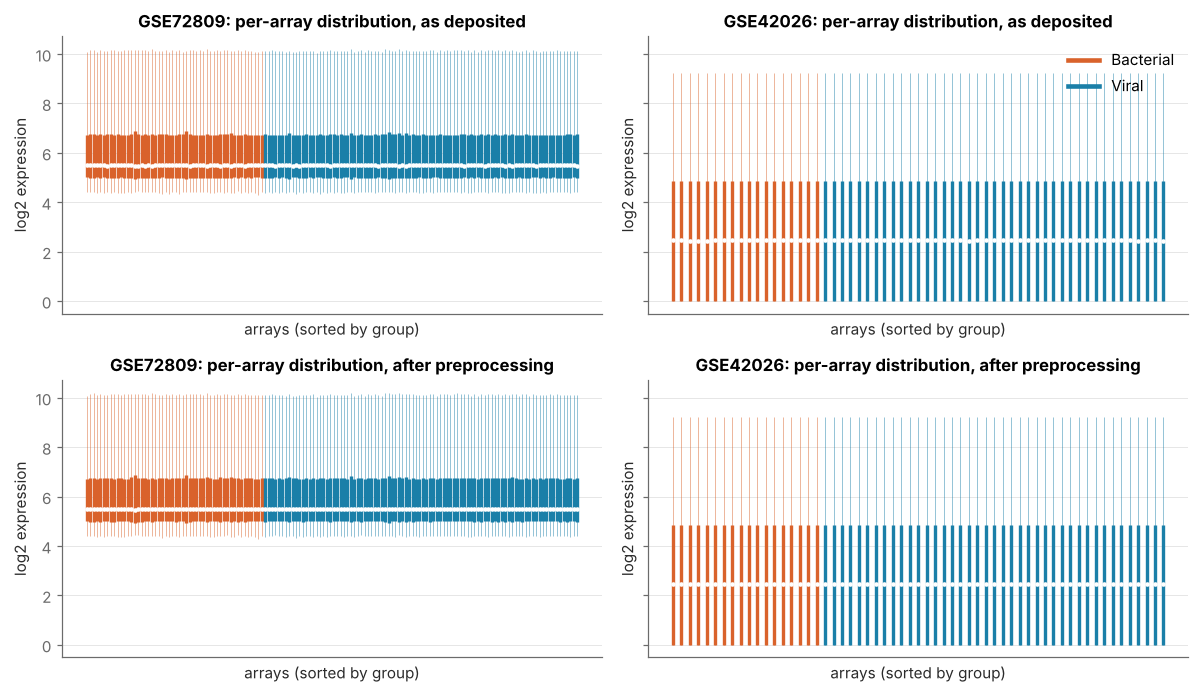

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharey="row")
for col, gse in enumerate(SOURCES):
    for row, (X, lab) in enumerate([(pre_norm[gse], "as deposited"), (data[gse]["expr"], "after preprocessing")]):
        ax = axes[row, col]
        grp = data[gse]["meta"]["group"]
        order = grp.sort_values().index
        q = X[order].quantile([0.05, 0.25, 0.5, 0.75, 0.95])
        xs = np.arange(len(order))
        c = [COL[g] for g in grp[order]]
        ax.vlines(xs, q.loc[0.05], q.loc[0.95], color=c, lw=0.6, alpha=0.5)
        ax.vlines(xs, q.loc[0.25], q.loc[0.75], color=c, lw=2.2)
        ax.scatter(xs, q.loc[0.5], s=4, color="white", zorder=3)
        ax.set(title=f"{gse}: per-array distribution, {lab}", xlabel="arrays (sorted by group)",
               ylabel="log2 expression", xticks=[])
for g, c in COL.items():
    axes[0, 1].plot([], [], color=c, lw=3, label=g)
axes[0, 1].legend(loc="upper right")
fig.tight_layout()
savefig(fig, "fig02_distributions")

**Figure 2.** Each vertical line is one array: the thick part spans the middle 50% of probe values, the thin part
5–95%, the white dot is the median.

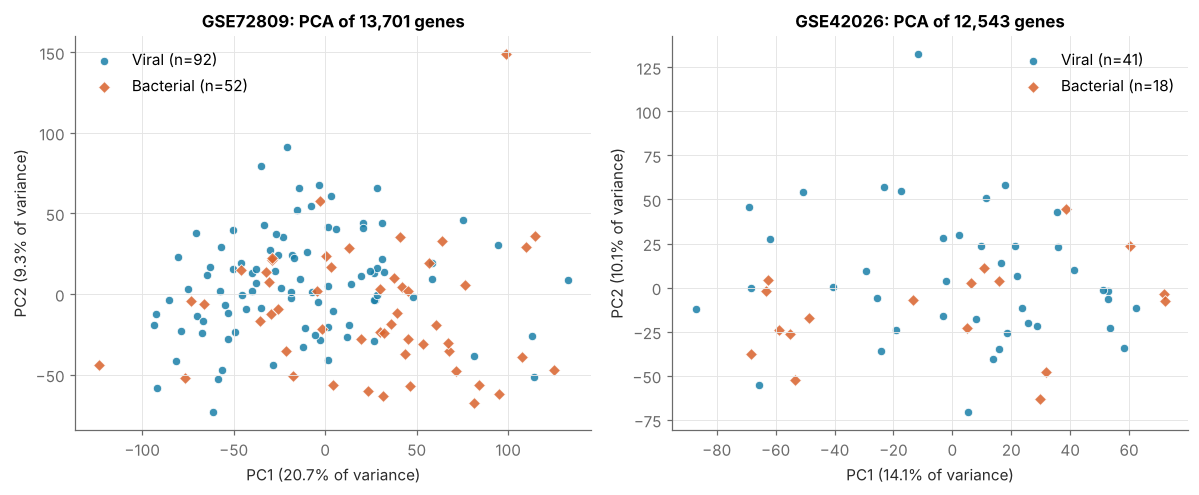

GSE72809 PC1: correlation with bacterial label r = +0.34 (p = 2.9e-05); top-loading genes: ADSL, NOL11, HACD3, MRPL45, NSMCE4A, BZW2, SNRPA1, RAB3D, POLR2H, HADH, CFAP298, URI1
GSE72809 PC2: correlation with bacterial label r = -0.23 (p = 5.6e-03); top-loading genes: RB1CC1, LAMTOR3, WBP4, STAG2, RAB3GAP2, UBL3, SLMAP, TMEM167A, CLK4, PPM1B, SNX14, ZDHHC17


In [15]:
def pca(X, n=5):
    X = X.loc[X.std(axis=1) > 0]  # constant genes carry no information and break the scaling
    Z = (X.T - X.T.mean()) / X.T.std(ddof=1)
    U, S, Vt = np.linalg.svd(Z.values, full_matrices=False)
    scores = pd.DataFrame(U[:, :n] * S[:n], index=X.columns, columns=[f"PC{i + 1}" for i in range(n)])
    load = pd.DataFrame(Vt[:n].T, index=X.index, columns=scores.columns)
    return scores, load, S ** 2 / (S ** 2).sum()


fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
pca_out = {}
for ax, (gse, G) in zip(axes, [(gse_d, Gd), (gse_t, Gt)]):
    sc, ld, ve = pca(G)
    pca_out[gse] = (sc, ld, ve)
    grp = data[gse]["meta"]["group"]
    for g in ["Viral", "Bacterial"]:
        m = grp == g
        ax.scatter(sc.loc[m, "PC1"], sc.loc[m, "PC2"], s=30, color=COL[g], alpha=0.85, edgecolor="white", lw=0.6,
                   label=f"{g} (n={m.sum()})", marker="o" if g == "Viral" else "D")
    ax.set(title=f"{gse}: PCA of {G.shape[0]:,} genes", xlabel=f"PC1 ({ve[0]:.1%} of variance)",
           ylabel=f"PC2 ({ve[1]:.1%} of variance)")
    ax.legend(loc="best")
fig.tight_layout()
savefig(fig, "fig03_pca")
sc, ld, ve = pca_out[gse_d]
for pc in ["PC1", "PC2"]:
    r = stats.pointbiserialr(yd, sc[pc])
    top = ld[pc].abs().sort_values(ascending=False).index[:12]
    print(f"{gse_d} {pc}: correlation with bacterial label r = {r.statistic:+.2f} (p = {r.pvalue:.1e}); "
          f"top-loading genes: {', '.join(top)}")

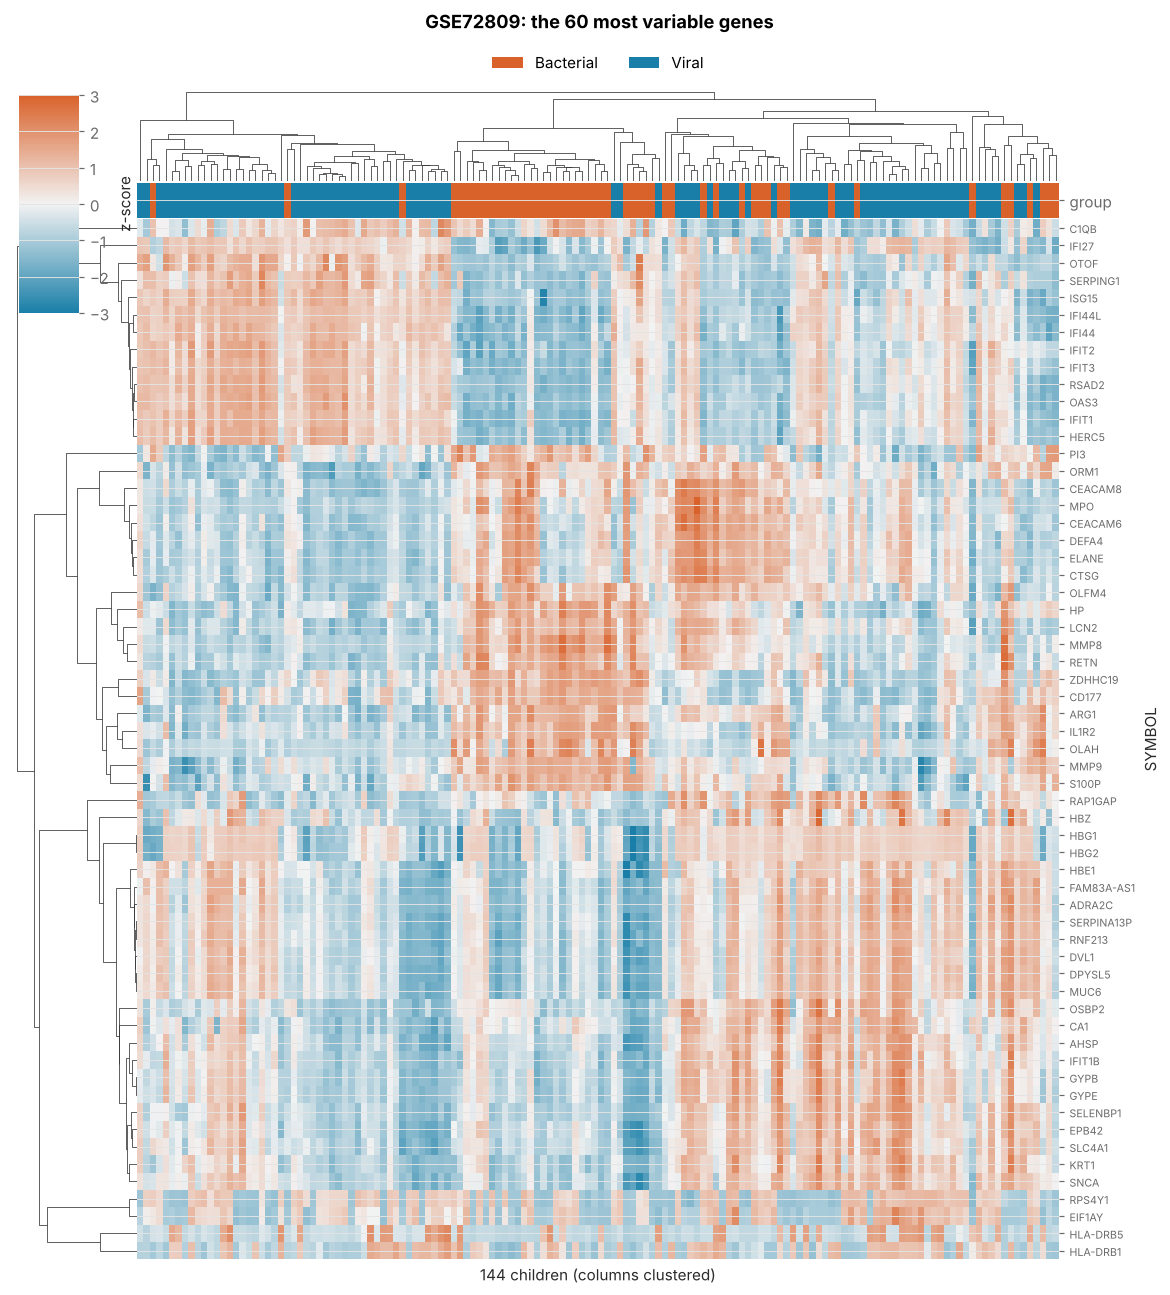

bacterial share in the two halves of the column dendrogram: 36% vs 36%


In [16]:
top_var = Gd.var(axis=1).sort_values(ascending=False).index[:60]
Z = Gd.loc[top_var].sub(Gd.loc[top_var].mean(axis=1), axis=0).div(Gd.loc[top_var].std(axis=1), axis=0).clip(-3, 3)
grp_d = data[gse_d]["meta"]["group"]
cg = sns.clustermap(Z, cmap=DIVERGING, center=0, vmin=-3, vmax=3, col_colors=grp_d.map(COL).rename("group"),
                    xticklabels=False, yticklabels=True, figsize=(11, 11), method="average", metric="correlation",
                    cbar_kws={"label": "z-score"}, dendrogram_ratio=(0.12, 0.08))
cg.ax_heatmap.set_xlabel(f"{Gd.shape[1]} children (columns clustered)")
cg.ax_heatmap.tick_params(axis="y", labelsize=7)
cg.fig.suptitle(f"{gse_d}: the 60 most variable genes", y=1.05, fontweight="bold")
for g, c in COL.items():
    cg.ax_col_dendrogram.bar(0, 0, color=c, label=g)
cg.ax_col_dendrogram.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, 1.02), frameon=False)
cg.fig.savefig(FIG / "fig04_heatmap_top_variable.png", bbox_inches="tight", facecolor="white")
plt.show()
col_order = Z.columns[cg.dendrogram_col.reordered_ind]
left, right = col_order[: len(col_order) // 2], col_order[len(col_order) // 2:]
print("bacterial share in the two halves of the column dendrogram:",
      f"{(grp_d[left] == 'Bacterial').mean():.0%} vs {(grp_d[right] == 'Bacterial').mean():.0%}")

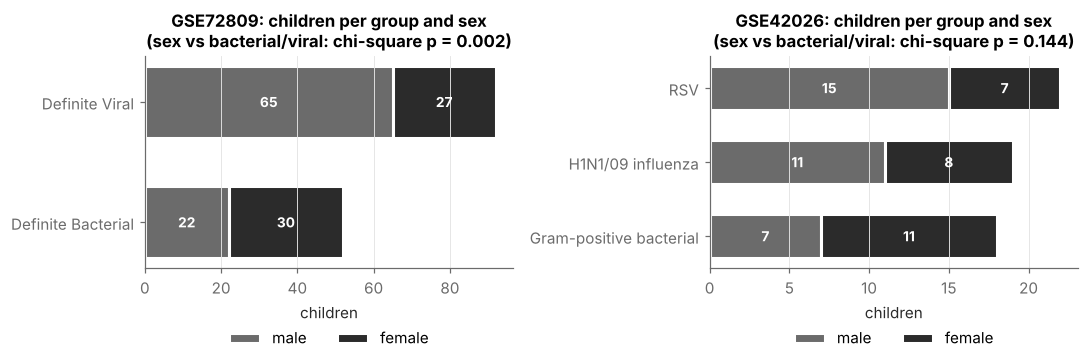

Neither series records age in the deposited metadata, so age could not be checked or adjusted for.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
demo = []
for ax, gse in zip(axes, SOURCES):
    m = data[gse]["meta"]
    tab = pd.crosstab(m["subtype"], m["sex_recorded"])
    chi = stats.chi2_contingency(pd.crosstab(m["group"], m["sex_recorded"]))
    demo.append(dict(dataset=gse, test="sex vs group (chi-square)", p=round(chi.pvalue, 3)))
    left = np.zeros(len(tab))
    for sx, c in [("male", MUTED), ("female", INK)]:
        v = tab.get(sx, pd.Series(0, index=tab.index)).values
        ax.barh(tab.index, v, left=left, color=c, height=0.6, label=sx, edgecolor="white", lw=2)
        for i, (l, w) in enumerate(zip(left, v)):
            if w:
                ax.text(l + w / 2, i, str(w), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += v
    ptxt = "p < 0.001" if chi.pvalue < 0.001 else f"p = {chi.pvalue:.3f}"
    ax.set(title=f"{gse}: children per group and sex\n(sex vs bacterial/viral: chi-square {ptxt})", xlabel="children")
    ax.grid(axis="y", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
fig.tight_layout()
savefig(fig, "fig_s1_demographics")
print("Neither series records age in the deposited metadata, so age could not be checked or adjusted for.")

**Interpretation.**
* **Distributions (Fig. 2).** After preprocessing, all arrays within each dataset share the same distribution, so
  remaining differences are biological or due to sample quality rather than array brightness.
* **PCA (Fig. 3).** The largest source of variation is **not** infection type. PC1 explains 20.7% of variance and
  correlates only moderately with the bacterial label (r = 0.34), and bacterial and viral children overlap heavily.
  Infection type is a real but secondary signal, so a classifier must pick the right genes rather than rely on
  overall expression.
* **Heatmap (Fig. 4).** The 60 most variable genes form clear biological blocks:
  * an **interferon** block (*IFI27, ISG15, IFI44L, RSAD2, OAS3, IFIT1–3*), high in a cluster of mostly viral children;
  * a **neutrophil granule** block (*MPO, ELANE, DEFA4, CEACAM8, LCN2, MMP8, ARG1, CD177*), high in many bacterial
    children;
  * an **erythroid** block (*HBG1/2, HBZ, SLC4A1, GYPB*), reflecting age and red-cell turnover;
  * **sex** (*RPS4Y1, EIF1AY*) and **HLA** genes, which vary between individuals regardless of infection.

  The top-level split of the dendrogram has the same bacterial share in both halves (36%), confirming that unselected
  high-variance genes mix infection signal with unrelated biology.
* **Demographics (Fig. S1).** In GSE72809, 58% of bacterial but only 29% of viral children are female
  (chi-square p = 0.002). Sex is therefore partly confounded with infection type in the discovery set, which is why
  Section 5 repeats the test adjusted for sex. The test set shows no significant imbalance (p = 0.14).

## 5. Core analysis: differential expression with FDR correction

**Method.** For every gene we fit a linear model (expression ~ group) and test the bacterial-minus-viral difference
with the **moderated t-statistic** of limma (Smyth 2004), implemented below in NumPy. With 144 children and thousands
of genes, each gene's variance estimate is shrunk towards a common value estimated from all genes (empirical Bayes),
which stabilises tests for genes with unusually small or large variance. P-values are corrected with the
Benjamini–Hochberg procedure. A gene is called differentially expressed (DE) at **FDR < 0.05**, and *strongly* DE if
it also changes at least two-fold (|log2 fold change| ≥ 1). As a check, an ordinary Welch t-test is run alongside.

In [18]:
def trigamma_inverse(x):
    y = 0.5 + 1.0 / x
    for _ in range(50):
        tri = polygamma(1, y)
        dif = tri * (1 - tri / x) / polygamma(2, y)
        y = y + dif
        if np.max(-dif / y) < 1e-8:
            break
    return y


def moderated_t(G, design, coef):
    """limma-style lmFit + eBayes for one coefficient. G: genes x samples. Returns a results table."""
    Y = G.values
    n, p = design.shape
    XtX_inv = np.linalg.inv(design.T @ design)
    beta = Y @ design @ XtX_inv
    resid = Y - beta @ design.T
    df_res = n - p
    s2 = (resid ** 2).sum(axis=1) / df_res
    e = np.log(s2) - digamma(df_res / 2) + np.log(df_res / 2)
    evar = e.var(ddof=1) - polygamma(1, df_res / 2)
    if evar > 0:
        d0 = 2 * trigamma_inverse(evar)
        s0sq = np.exp(e.mean() + digamma(d0 / 2) - np.log(d0 / 2))
        s2_post = (d0 * s0sq + df_res * s2) / (d0 + df_res)
    else:
        d0, s0sq = np.inf, np.exp(e.mean())
        s2_post = np.full_like(s2, s0sq)
    df_tot = min(df_res + d0, df_res * len(s2))
    t = beta[:, coef] / np.sqrt(s2_post * XtX_inv[coef, coef])
    pval = 2 * stats.t.sf(np.abs(t), df_tot)
    out = pd.DataFrame({"log2FC": beta[:, coef], "mean_expr": Y.mean(axis=1), "t": t, "p": pval}, index=G.index)
    out["FDR"] = stats.false_discovery_control(out["p"], method="bh")
    out.attrs.update(d0=float(d0), s0sq=float(s0sq), df_total=float(df_tot))
    return out.sort_values("p")


design_d = np.column_stack([np.ones(len(yd)), yd])
de = moderated_t(Gd, design_d, coef=1)
welch = stats.ttest_ind(Gd.loc[:, yd == 1], Gd.loc[:, yd == 0], axis=1, equal_var=False)
de["welch_p"] = pd.Series(welch.pvalue, index=Gd.index)
de["welch_FDR"] = stats.false_discovery_control(de["welch_p"], method="bh")
de["direction"] = np.where(de["log2FC"] > 0, "higher in bacterial", "higher in viral")
de.index.name = "gene"
de.to_csv(RES / "de_GSE72809_bacterial_vs_viral.csv")
sig = de[de["FDR"] < 0.05]
strong = sig[sig["log2FC"].abs() >= 1]
print(f"prior: d0 = {de.attrs['d0']:.2f} extra degrees of freedom, s0 = {np.sqrt(de.attrs['s0sq']):.3f}")
print(f"genes tested: {len(de):,}")
print(f"DE at FDR < 0.05: {len(sig):,} ({(sig.log2FC > 0).sum():,} higher in bacterial, {(sig.log2FC < 0).sum():,} higher in viral)")
print(f"strongly DE (FDR < 0.05 and |log2FC| >= 1): {len(strong):,} ({(strong.log2FC > 0).sum()} bacterial, {(strong.log2FC < 0).sum()} viral)")
print(f"Welch t-test agrees on {((de.FDR < 0.05) == (de.welch_FDR < 0.05)).mean():.1%} of calls; "
      f"Spearman rho between the two p-value rankings = {stats.spearmanr(de.p, de.welch_p).statistic:.3f}")

prior: d0 = 4.65 extra degrees of freedom, s0 = 0.399
genes tested: 13,701
DE at FDR < 0.05: 5,760 (2,506 higher in bacterial, 3,254 higher in viral)
strongly DE (FDR < 0.05 and |log2FC| >= 1): 210 (101 bacterial, 109 viral)
Welch t-test agrees on 98.2% of calls; Spearman rho between the two p-value rankings = 0.998


In [19]:
# Sensitivity: repeat the test without the QC-flagged discovery arrays (Section 3.4 decision)
keep_d = ~Gd.columns.isin(qc_flagged[gse_d])
de_s = moderated_t(Gd.loc[:, keep_d], np.column_stack([np.ones(keep_d.sum()), yd[keep_d]]), coef=1)
strong_s = de_s[(de_s.FDR < 0.05) & (de_s.log2FC.abs() >= 1)]
# Sensitivity: adjust for recorded sex, because sex is unevenly split between the groups (Section 4)
male_d = (data[gse_d]["meta"]["sex_recorded"] == "male").astype(int).values
de_sex = moderated_t(Gd, np.column_stack([np.ones(len(yd)), yd, male_d]), coef=1)
strong_sex = de_sex[(de_sex.FDR < 0.05) & (de_sex.log2FC.abs() >= 1)]
print(f"adjusted for sex: rho = {stats.spearmanr(de.t, de_sex.t.reindex(de.index)).statistic:.3f}; "
      f"{len(set(strong.index) & set(strong_sex.index))}/{len(strong)} strongly DE genes remain ({len(strong_sex)} in total); "
      f"sex genes among the primary strongly DE list: {sorted(set(strong.index) & {'XIST', 'RPS4Y1', 'DDX3Y', 'KDM5D', 'EIF1AY', 'UTY', 'KDM5C'}) or 'none'}")
print(f"without {(~keep_d).sum()} flagged arrays: t-statistics correlate rho = "
      f"{stats.spearmanr(de.t, de_s.t.reindex(de.index)).statistic:.3f} with the primary analysis; "
      f"{len(set(strong.index) & set(strong_s.index))}/{len(strong)} strongly DE genes are still strongly DE "
      f"({len(strong_s)} in total)")

adjusted for sex: rho = 0.990; 202/210 strongly DE genes remain (218 in total); sex genes among the primary strongly DE list: ['EIF1AY', 'RPS4Y1']
without 7 flagged arrays: t-statistics correlate rho = 0.995 with the primary analysis; 206/210 strongly DE genes are still strongly DE (225 in total)


In [20]:
def top_table(df, direction, n=15):
    t = df[df["direction"] == direction].sort_values("p").head(n)
    return t[["log2FC", "mean_expr", "t", "p", "FDR"]].assign(fold_change=lambda x: 2 ** x.log2FC.abs()).round(
        {"log2FC": 2, "mean_expr": 2, "t": 2, "fold_change": 2})


fmt = {"p": "{:.1e}", "FDR": "{:.1e}"}
print("Top 15 genes higher in BACTERIAL infection")
display(top_table(de, "higher in bacterial").style.format(fmt))
print("Top 15 genes higher in VIRAL infection")
display(top_table(de, "higher in viral").style.format(fmt))

Top 15 genes higher in BACTERIAL infection


,log2FC,mean_expr,t,p,FDR,fold_change
gene,,,,,,
RFLNB,1.250000,8.420000,10.510000,1.3e-19,1.7e-16,2.380000
S100P,2.350000,10.460000,10.170000,1.0e-18,8.3e-16,5.090000
TDRD9,1.710000,7.430000,9.880000,5.9e-18,4.0e-15,3.280000
SLC25A40,0.900000,7.140000,9.630000,2.5e-17,1.5e-14,1.860000
SGSH,0.880000,8.990000,9.560000,4.0e-17,2.2e-14,1.840000
ANO10,0.800000,6.380000,9.520000,4.9e-17,2.6e-14,1.740000
OPLAH,1.930000,7.910000,9.510000,5.2e-17,2.7e-14,3.800000
SLC26A11,0.600000,6.780000,9.450000,7.4e-17,3.5e-14,1.520000
PECR,0.930000,8.240000,9.330000,1.5e-16,6.6e-14,1.910000


Top 15 genes higher in VIRAL infection


,log2FC,mean_expr,t,p,FDR,fold_change
gene,,,,,,
IFI44L,-3.790000,10.800000,-12.570000,4.8e-25,6.5e-21,13.840000
IFI27,-4.320000,11.960000,-12.260000,3.1e-24,2.2e-20,19.940000
EPSTI1,-2.230000,11.390000,-11.680000,1.0e-22,4.8e-19,4.700000
IFIT1,-3.490000,10.280000,-11.500000,3.2e-22,1.1e-18,11.270000
IFI44,-2.850000,10.170000,-11.400000,6.0e-22,1.7e-18,7.220000
RSAD2,-3.280000,9.640000,-11.090000,4.0e-21,9.1e-18,9.730000
OAS2,-2.050000,11.620000,-11.050000,5.0e-21,9.8e-18,4.130000
LY6E,-2.090000,12.680000,-10.930000,1.0e-20,1.7e-17,4.250000
XAF1,-2.190000,10.950000,-10.800000,2.3e-20,3.5e-17,4.550000


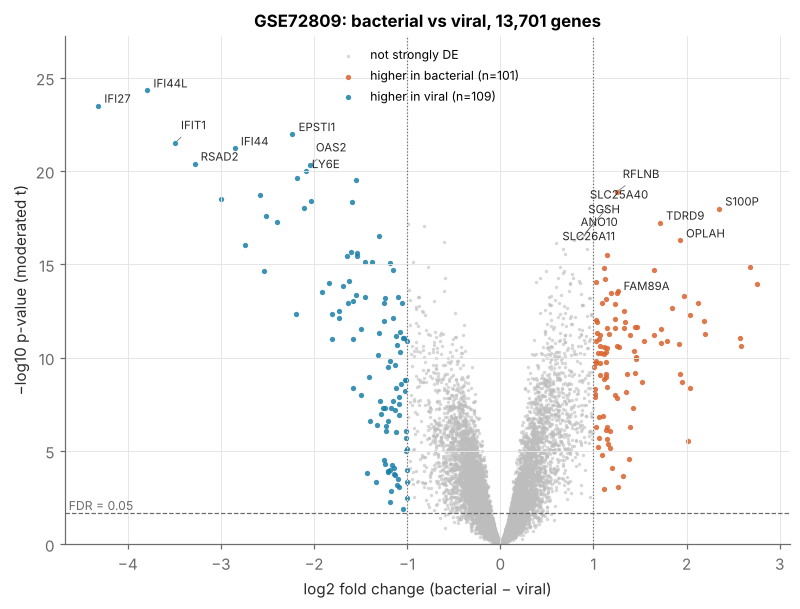

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 6))
nl = -np.log10(de["p"])
base = (de["FDR"] >= 0.05) | (de["log2FC"].abs() < 1)
ax.scatter(de.loc[base, "log2FC"], nl[base], s=5, color="#BDBDBD", alpha=0.6, lw=0, label="not strongly DE")
for g, mask in [("Bacterial", (~base) & (de.log2FC > 0)), ("Viral", (~base) & (de.log2FC < 0))]:
    ax.scatter(de.loc[mask, "log2FC"], nl[mask], s=12, color=COL[g], alpha=0.85, lw=0,
               label=f"higher in {g.lower()} (n={mask.sum()})")
fdr_line = nl[de["FDR"] < 0.05].min() if (de["FDR"] < 0.05).any() else None
if fdr_line is not None:
    ax.axhline(fdr_line, color=MUTED, ls="--", lw=0.8)
    ax.text(ax.get_xlim()[0] if de.log2FC.min() < 0 else 0, fdr_line, " FDR = 0.05", va="bottom", fontsize=8, color=MUTED)
for v in (-1, 1):
    ax.axvline(v, color=MUTED, ls=":", lw=0.8)
lab = pd.concat([de[de.log2FC > 0].head(8), de[de.log2FC < 0].head(8),
                 de.loc[[g for g in ["FAM89A", "IFI44L"] if g in de.index]]])
lab = lab[~lab.index.duplicated()]
ax.set_ylim(0, nl.max() * 1.12)
annotate_nonoverlap(ax, lab.log2FC.values, -np.log10(lab.p.values), list(lab.index))
ax.set(title=f"{gse_d}: bacterial vs viral, {len(de):,} genes", xlabel="log2 fold change (bacterial − viral)",
       ylabel="−log10 p-value (moderated t)")
ax.legend(loc="upper center", fontsize=8)
savefig(fig, "fig05_volcano")

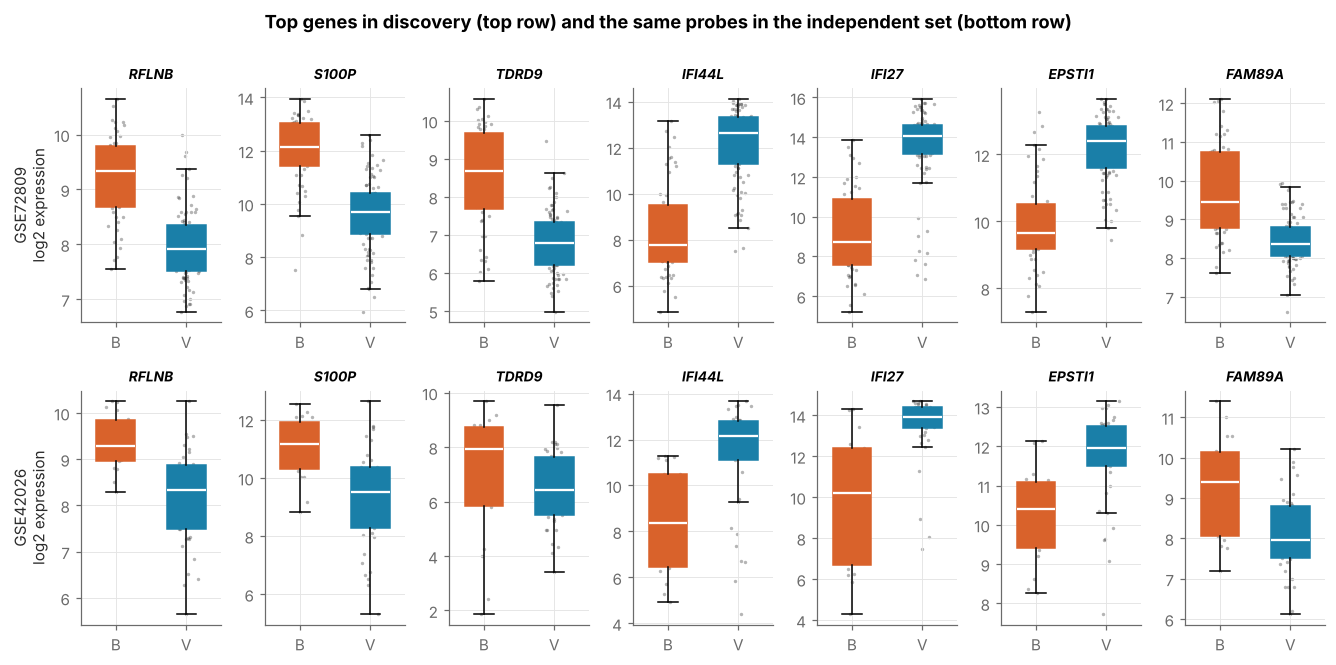

In [22]:
show = list(de[de.log2FC > 0].head(3).index) + list(de[de.log2FC < 0].head(3).index)
show += [g for g in ["FAM89A", "IFI44L"] if g in de.index and g not in show]
fig, axes = plt.subplots(2, len(show), figsize=(1.75 * len(show), 6), sharey=False)
for row, (gse, G) in enumerate([(gse_d, Gd), (gse_t, Gt)]):
    grp = data[gse]["meta"]["group"]
    for ax, g in zip(axes[row], show):
        if g not in G.index:
            ax.set_axis_off()
            ax.set_title(f"{g}\n(not on V3)", fontsize=8)
            continue
        vals = [G.loc[g, grp == k].values for k in ["Bacterial", "Viral"]]
        bp = ax.boxplot(vals, widths=0.55, patch_artist=True, showfliers=False, medianprops=dict(color="white", lw=1.5))
        for patch, k in zip(bp["boxes"], ["Bacterial", "Viral"]):
            patch.set_facecolor(COL[k])
            patch.set_edgecolor(COL[k])
        for i, v in enumerate(vals):
            ax.scatter(np.random.default_rng(SEED).normal(i + 1, 0.07, len(v)), v, s=5, color=INK, alpha=0.35, lw=0)
        ax.set_xticks([1, 2], ["B", "V"])
        ax.set_title(g, fontsize=9, fontstyle="italic")
        if ax is axes[row][0]:
            ax.set_ylabel(f"{gse}\nlog2 expression")
fig.suptitle("Top genes in discovery (top row) and the same probes in the independent set (bottom row)",
             fontweight="bold", y=1.0)
fig.tight_layout()
savefig(fig, "fig06_top_genes_boxplots")

### 5.1 Do the differences replicate in the independent dataset?
The same moderated t-test is run in GSE42026 on the genes measured there. Replication is judged by direction and
nominal significance of the discovery DE genes, and by the correlation of fold changes across the two cohorts.

genes in both datasets: 12,543; discovery DE genes measured in test set: 5,386
same direction in GSE42026: 81.8%; same direction AND p < 0.05: 30.4%
strongly DE genes replicated (same direction, p < 0.05): 140/205
fold-change correlation: all genes r = 0.60; discovery DE genes r = 0.75 (p = 0.0e+00)
DE at FDR < 0.05 within GSE42026 alone: 882 genes


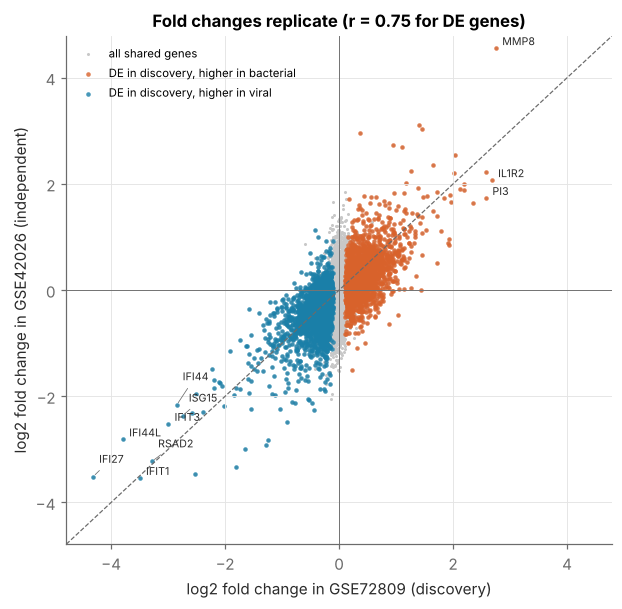

In [23]:
design_t = np.column_stack([np.ones(len(yt)), yt])
de_t = moderated_t(Gt, design_t, coef=1)
de_t.index.name = "gene"
de_t.to_csv(RES / "de_GSE42026_bacterial_vs_viral.csv")
both = de.join(de_t, rsuffix="_test", how="inner")
sig_both = both[both["FDR"] < 0.05]
same_dir = np.sign(sig_both.log2FC) == np.sign(sig_both.log2FC_test)
rep = same_dir & (sig_both.p_test < 0.05)
r_all = stats.pearsonr(both.log2FC, both.log2FC_test)
r_sig = stats.pearsonr(sig_both.log2FC, sig_both.log2FC_test)
strong_both = sig_both[sig_both.log2FC.abs() >= 1]
rep_strong = ((np.sign(strong_both.log2FC) == np.sign(strong_both.log2FC_test)) & (strong_both.p_test < 0.05))
print(f"genes in both datasets: {len(both):,}; discovery DE genes measured in test set: {len(sig_both):,}")
print(f"same direction in GSE42026: {same_dir.mean():.1%}; same direction AND p < 0.05: {rep.mean():.1%}")
print(f"strongly DE genes replicated (same direction, p < 0.05): {rep_strong.sum()}/{len(strong_both)}")
print(f"fold-change correlation: all genes r = {r_all.statistic:.2f}; discovery DE genes r = {r_sig.statistic:.2f} (p = {r_sig.pvalue:.1e})")
print(f"DE at FDR < 0.05 within GSE42026 alone: {(de_t.FDR < 0.05).sum():,} genes")

fig, ax = plt.subplots(figsize=(6.4, 6))
ax.scatter(both.log2FC, both.log2FC_test, s=4, color="#C8C8C8", lw=0, label="all shared genes")
for g, m in [("Bacterial", sig_both.log2FC > 0), ("Viral", sig_both.log2FC < 0)]:
    ax.scatter(sig_both.loc[m, "log2FC"], sig_both.loc[m, "log2FC_test"], s=9, color=COL[g], alpha=0.8, lw=0,
               label=f"DE in discovery, higher in {g.lower()}")
lim = np.nanmax(np.abs(both[["log2FC", "log2FC_test"]].values)) * 1.05
ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=0.8, ls="--")
ax.axhline(0, color=MUTED, lw=0.6)
ax.axvline(0, color=MUTED, lw=0.6)
ax.set(xlim=(-lim, lim), ylim=(-lim, lim))
lab_g = list(strong_both.log2FC.abs().sort_values(ascending=False).index[:10])
annotate_nonoverlap(ax, both.loc[lab_g, "log2FC"].values, both.loc[lab_g, "log2FC_test"].values, lab_g, fontsize=7)
ax.set(xlabel=f"log2 fold change in {gse_d} (discovery)",
       ylabel=f"log2 fold change in {gse_t} (independent)",
       title=f"Fold changes replicate (r = {r_sig.statistic:.2f} for DE genes)")
ax.legend(loc="upper left", fontsize=7.5)
savefig(fig, "fig07_replication")

**Interpretation.**
* **Overall.** H0 is rejected. Of 13,701 genes, **5,760 differ at FDR < 0.05** (2,506 higher in bacterial, 3,254
  higher in viral). **210 differ strongly** (≥ two-fold): 101 bacterial and 109 viral. The empirical-Bayes prior adds
  4.7 degrees of freedom, and the ordinary Welch test reaches the same call for 98.2% of genes, so the result does not
  depend on the variance-shrinkage choice.
* **Viral side.** The most significant genes are classic **interferon-stimulated genes**: *IFI44L* (rank 1,
  ≈ 14-fold higher in viral), *IFI27* (rank 2, ≈ 20-fold), *EPSTI1, IFIT1, IFI44, RSAD2, OAS2, LY6E, XAF1* and *MX1*.
* **Bacterial side.** Neutrophil and inflammatory genes lead: *S100P, IL1R2, MMP8* (≈ 7-fold), *PI3, ZDHHC19,
  OPLAH, TDRD9*, and *FAM89A* (rank 77).
* **Sensitivity analyses.**
  * Adjusting for sex keeps 202 of the 210 strongly DE genes (rank correlation of t-statistics 0.990). The Y-linked
    *RPS4Y1* and *EIF1AY* reach the unadjusted list only because bacterial cases are more often female. They are a
    confounding artefact, not infection biology.
  * Removing the 7 QC-flagged arrays keeps 206/210.
* **Replication (Fig. 7).** In the independent cohort, 81.8% of discovery DE genes change in the same direction, and
  140 of the 205 measurable strongly DE genes (68%) replicate with p < 0.05. Fold changes correlate at r = 0.75. The
  host response is reproducible across cohort, chip version and processing pipeline. Fewer genes reach FDR < 0.05
  within GSE42026 alone (882), as expected from its much smaller size.

## 6. Biological interpretation

### 6.1 Over-representation analysis (GO biological process and Hallmark pathways)
For each direction we ask whether the strongly DE genes contain more members of a gene set than expected by chance,
using a one-sided hypergeometric test and Benjamini–Hochberg correction. The background (universe) is every gene that
passed filtering in Section 3, not the whole genome, because a gene that was never measurable could never have been
called DE. Sets with fewer than 10 or more than 500 measurable genes are skipped.

In [24]:
def read_gmt(path):
    sets = {}
    with open(path) as fh:
        for line in fh:
            parts = line.rstrip("\n").split("\t")
            sets[parts[0]] = {g for g in parts[2:] if g}
    return sets


def ora(genes, universe, gene_sets, min_size=10, max_size=500):
    universe = set(universe)
    genes = set(genes) & universe
    N, n = len(universe), len(genes)
    rows = []
    for term, members in gene_sets.items():
        m = members & universe
        K = len(m)
        if K < min_size or K > max_size:
            continue
        hits = genes & m
        k = len(hits)
        if k == 0:
            continue
        rows.append(dict(term=term, set_size=K, overlap=k, fold_enrichment=(k / n) / (K / N),
                         p=stats.hypergeom.sf(k - 1, N, K, n), genes=", ".join(sorted(hits))))
    out = pd.DataFrame(rows)
    out["FDR"] = stats.false_discovery_control(out["p"], method="bh")
    return out.sort_values("p").reset_index(drop=True)


libraries = {"GO BP 2021": read_gmt(files["GO_Biological_Process_2021.gmt"][0]),
             "Hallmark": read_gmt(files["MSigDB_Hallmark_v7.0.gmt"][0])}
universe = list(de.index)
enrich = {}
for lib, gs in libraries.items():
    for direction, gl in [("bacterial", strong[strong.log2FC > 0].index), ("viral", strong[strong.log2FC < 0].index)]:
        r = ora(gl, universe, gs)
        enrich[(lib, direction)] = r
        r.to_csv(RES / f"ora_{lib.replace(' ', '_')}_{direction}.csv", index=False)
        print(f"{lib:10s} | higher in {direction:9s}: {len(gl):4d} genes -> {int((r.FDR < 0.05).sum()):3d} sets at FDR < 0.05")

for key in [("Hallmark", "bacterial"), ("Hallmark", "viral"), ("GO BP 2021", "bacterial"), ("GO BP 2021", "viral")]:
    print(f"\n{key[0]} — higher in {key[1]} infection (top 8)")
    display(enrich[key].head(8)[["term", "set_size", "overlap", "fold_enrichment", "FDR", "genes"]]
            .assign(genes=lambda x: x.genes.str.slice(0, 90)).style.format({"fold_enrichment": "{:.1f}", "FDR": "{:.1e}"}))

GO BP 2021 | higher in bacterial:  101 genes ->  12 sets at FDR < 0.05
GO BP 2021 | higher in viral    :  109 genes -> 100 sets at FDR < 0.05
Hallmark   | higher in bacterial:  101 genes ->   0 sets at FDR < 0.05
Hallmark   | higher in viral    :  109 genes ->   8 sets at FDR < 0.05

Hallmark — higher in bacterial infection (top 8)


,term,set_size,overlap,fold_enrichment,FDR,genes
0,HALLMARK_XENOBIOTIC_METABOLISM,143,5,4.7,1.0e-01,"ARG1, PGD, TPST1, UPB1, VNN1"
1,HALLMARK_KRAS_SIGNALING_UP,142,4,3.8,2.1e-01,"ARG1, MMP9, RETN, SLPI"
2,HALLMARK_COAGULATION,86,3,4.7,2.1e-01,"GSN, MMP8, MMP9"
3,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,122,3,3.3,3.3e-01,"ANPEP, GADD45A, PCOLCE2"
4,HALLMARK_APICAL_JUNCTION,136,3,3.0,3.3e-01,"COL17A1, MMP9, MPZL1"
5,HALLMARK_APOPTOSIS,140,3,2.9,3.3e-01,"GADD45A, GSN, IER3"
6,HALLMARK_IL6_JAK_STAT3_SIGNALING,70,2,3.9,3.3e-01,"EBI3, IL1R2"
7,HALLMARK_GLYCOLYSIS,156,3,2.6,3.3e-01,"IER3, PYGL, TPST1"



Hallmark — higher in viral infection (top 8)


,term,set_size,overlap,fold_enrichment,FDR,genes
0,HALLMARK_INTERFERON_GAMMA_RESPONSE,185,44,29.9,2.1e-53,"BATF2, CCL2, CCL5, CMPK2, CXCL10, DDX60, DHX58, EIF2AK2, EPSTI1, GBP4, GZMA, HELZ2, HERC6,"
1,HALLMARK_INTERFERON_ALPHA_RESPONSE,91,36,49.7,1.2e-52,"BATF2, CMPK2, CXCL10, DDX60, DHX58, EIF2AK2, EPSTI1, GBP4, HELZ2, HERC6, IFI27, IFI35, IFI"
2,HALLMARK_ALLOGRAFT_REJECTION,168,9,6.7,7.0e-05,"CCL2, CCL5, GZMA, GZMB, IRF7, KLRD1, KRT1, PRF1, STAT1"
3,HALLMARK_INFLAMMATORY_RESPONSE,164,8,6.1,3.4e-04,"CCL2, CCL5, CXCL10, EIF2AK2, IRF7, LAMP3, LY6E, RTP4"
4,HALLMARK_KRAS_SIGNALING_DN,99,5,6.3,6.4e-03,"ADRA2C, IFI44L, KRT1, MX1, RSAD2"
5,HALLMARK_COMPLEMENT,166,6,4.5,9.8e-03,"CCL5, GZMA, GZMB, IRF7, LAP3, SERPING1"
6,HALLMARK_TNFA_SIGNALING_VIA_NFKB,171,5,3.7,4.7e-02,"CCL2, CCL5, CXCL10, IFIH1, IFIT2"
7,HALLMARK_HEME_METABOLISM,177,5,3.6,4.7e-02,"GYPB, GYPE, HBZ, MYL4, SNCA"



GO BP 2021 — higher in bacterial infection (top 8)


,term,set_size,overlap,fold_enrichment,FDR,genes
0,neutrophil degranulation (GO:0043312),447,37,11.2,5.7e-27,"ANPEP, ANXA3, ARG1, BPI, CD177, CD63, CEACAM8, CKAP4, CTSG, CYSTM1, DEFA4, ELANE, GPR84, G"
1,neutrophil activation involved in immune response (GO:0002283),450,37,11.2,5.7e-27,"ANPEP, ANXA3, ARG1, BPI, CD177, CD63, CEACAM8, CKAP4, CTSG, CYSTM1, DEFA4, ELANE, GPR84, G"
2,neutrophil mediated immunity (GO:0002446),452,37,11.1,5.7e-27,"ANPEP, ANXA3, ARG1, BPI, CD177, CD63, CEACAM8, CKAP4, CTSG, CYSTM1, DEFA4, ELANE, GPR84, G"
3,defense response to bacterium (GO:0042742),105,13,16.8,1.1e-10,"ANXA3, BPI, CTSG, DEFA4, ELANE, LCN2, MPO, NLRC4, PGLYRP1, PI3, RNASE3, S100A12, SLPI"
4,antibacterial humoral response (GO:0019731),25,5,27.1,1.2e-04,"CTSG, DEFA4, PI3, RNASE3, SLPI"
5,extracellular matrix disassembly (GO:0022617),31,5,21.9,3.0e-04,"CTSG, ELANE, GSN, MMP8, MMP9"
6,cellular component disassembly (GO:0022411),32,5,21.2,3.0e-04,"CTSG, ELANE, GSN, MMP8, MMP9"
7,defense response to Gram-negative bacterium (GO:0050829),41,5,16.5,9.3e-04,"BPI, CTSG, DEFA4, ELANE, RNASE3"



GO BP 2021 — higher in viral infection (top 8)


,term,set_size,overlap,fold_enrichment,FDR,genes
0,defense response to virus (GO:0051607),114,27,29.8,3.3e-30,"CXCL10, EIF2AK2, IFI27, IFI44L, IFI6, IFIH1, IFIT1, IFIT1B, IFIT2, IFIT3, IFIT5, IFITM3, I"
1,defense response to symbiont (GO:0140546),107,26,30.5,1.3e-29,"EIF2AK2, IFI27, IFI44L, IFI6, IFIH1, IFIT1, IFIT1B, IFIT2, IFIT3, IFIT5, IFITM3, IRF7, ISG"
2,type I interferon signaling pathway (GO:0060337),53,19,45.1,4.6e-25,"IFI27, IFI35, IFI6, IFIT1, IFIT2, IFIT3, IFIT5, IFITM3, IRF7, ISG15, MX1, OAS1, OAS2, OAS3"
3,cellular response to type I interferon (GO:0071357),53,19,45.1,4.6e-25,"IFI27, IFI35, IFI6, IFIT1, IFIT2, IFIT3, IFIT5, IFITM3, IRF7, ISG15, MX1, OAS1, OAS2, OAS3"
4,negative regulation of viral process (GO:0048525),60,14,29.3,3.4e-15,"CCL5, EIF2AK2, IFIH1, IFIT1, IFIT5, IFITM3, ISG15, MX1, OAS1, OAS2, OAS3, OASL, RSAD2, STA"
5,negative regulation of viral genome replication (GO:0045071),49,13,33.3,6.5e-15,"CCL5, EIF2AK2, IFIH1, IFIT1, IFIT5, IFITM3, ISG15, MX1, OAS1, OAS2, OAS3, OASL, RSAD2"
6,cellular response to interferon-gamma (GO:0071346),92,15,20.5,5.2e-14,"CCL2, CCL5, CCL8, GBP1, GBP4, GBP5, HLA-DRB5, IRF7, MT2A, OAS1, OAS2, OAS3, OASL, STAT1, T"
7,cytokine-mediated signaling pathway (GO:0019221),492,27,6.9,8.0e-14,"CCL2, CCL5, CCL8, CXCL10, GBP1, HLA-DRB5, IFI27, IFI35, IFI6, IFIT1, IFIT2, IFIT3, IFIT5,"


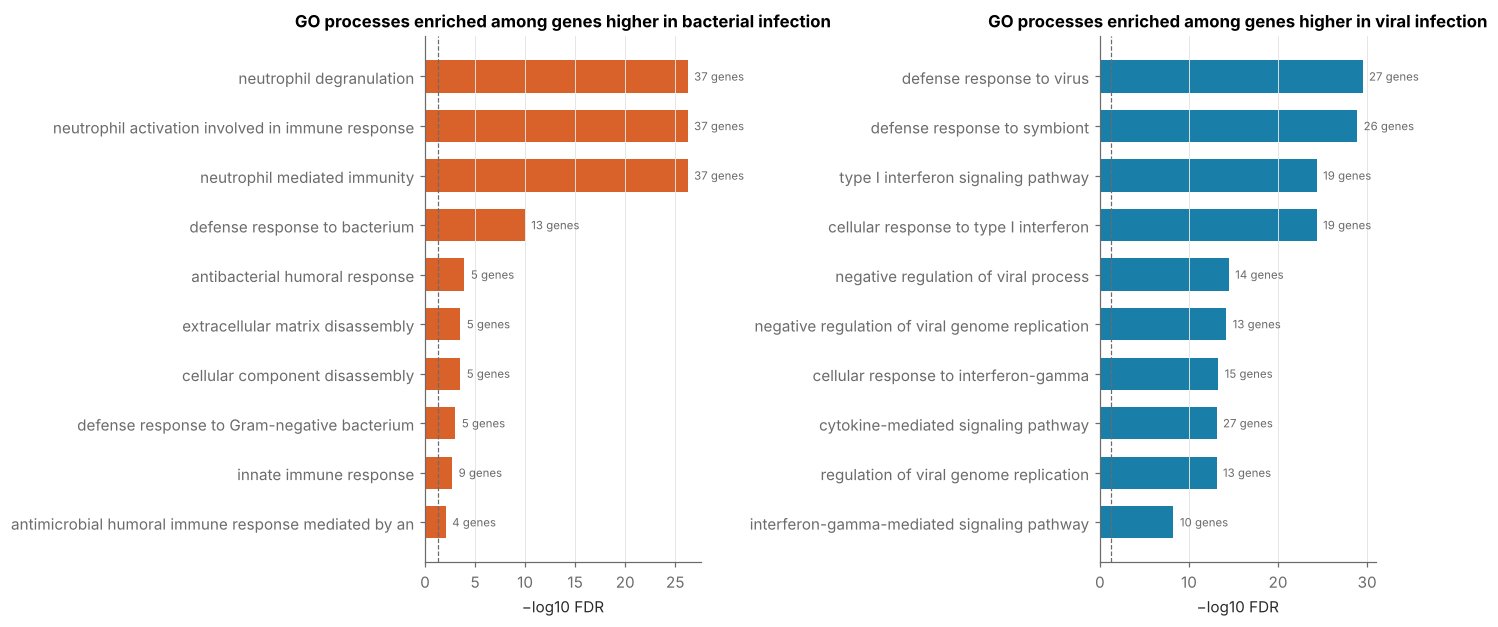

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, direction in zip(axes, ["bacterial", "viral"]):
    r = enrich[("GO BP 2021", direction)].head(10).iloc[::-1]
    lab = r.term.str.replace(r"\s*\(GO:\d+\)", "", regex=True).str.slice(0, 52)
    ax.barh(lab, -np.log10(r.FDR), color=COL[direction.capitalize()], height=0.65)
    for i, (v, k) in enumerate(zip(-np.log10(r.FDR), r.overlap)):
        ax.text(v, i, f"  {k} genes", va="center", fontsize=7.5, color=MUTED)
    ax.axvline(-np.log10(0.05), color=MUTED, ls="--", lw=0.8)
    ax.set(title=f"GO processes enriched among genes higher in {direction} infection", xlabel="−log10 FDR")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "fig08_go_enrichment")

### 6.2 Co-expression network of the top DE genes (NetworkX)
Genes that act in the same pathway tend to rise and fall together across children. We connect the 40 most
significant genes in each direction when their expression correlates strongly (|Pearson r| ≥ 0.7 across the 144
discovery children) and look for communities (modules) with greedy modularity optimisation.

,module,n_genes,composition,hub_genes
0,1,44,"37 bacterial, 7 viral","SLC25A40, OPLAH, TDRD9, RFLNB, ANO10, TMCO3"
1,2,33,33 viral,"OAS2, IFI44L, LY6E, EPSTI1, PARP12, XAF1"


network: 77 genes, 796 edges; modularity = 0.40


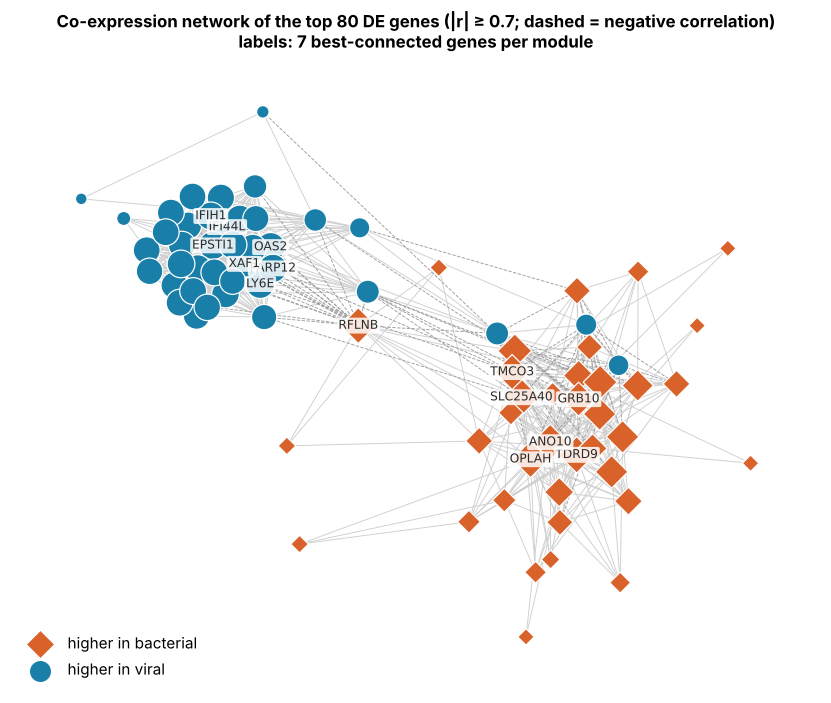

In [26]:
net_genes = list(de[de.log2FC > 0].head(40).index) + list(de[de.log2FC < 0].head(40).index)
R = np.corrcoef(Gd.loc[net_genes].values)
Gnet = nx.Graph()
for g in net_genes:
    Gnet.add_node(g, direction="Bacterial" if de.loc[g, "log2FC"] > 0 else "Viral")
for i in range(len(net_genes)):
    for j in range(i + 1, len(net_genes)):
        if abs(R[i, j]) >= 0.7:
            Gnet.add_edge(net_genes[i], net_genes[j], weight=abs(R[i, j]), sign=np.sign(R[i, j]))
Gnet.remove_nodes_from([n for n in list(Gnet) if Gnet.degree(n) == 0])
comms = sorted(nx.algorithms.community.greedy_modularity_communities(Gnet, weight="weight"), key=len, reverse=True)
deg = dict(Gnet.degree())
mod_rows = []
for k, cset in enumerate(comms):
    dirs = pd.Series([Gnet.nodes[n]["direction"] for n in cset]).value_counts()
    hubs = sorted(cset, key=lambda n: -deg[n])[:6]
    mod_rows.append(dict(module=k + 1, n_genes=len(cset), composition=", ".join(f"{v} {i.lower()}" for i, v in dirs.items()),
                         hub_genes=", ".join(hubs)))
modules = pd.DataFrame(mod_rows)
display(modules)
print(f"network: {Gnet.number_of_nodes()} genes, {Gnet.number_of_edges()} edges; "
      f"modularity = {nx.algorithms.community.modularity(Gnet, comms, weight='weight'):.2f}")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
pos = nx.spring_layout(Gnet, seed=SEED, k=0.6, weight="weight")
neg_edges = [(u, v) for u, v, d in Gnet.edges(data=True) if d["sign"] < 0]
pos_edges = [(u, v) for u, v, d in Gnet.edges(data=True) if d["sign"] > 0]
nx.draw_networkx_edges(Gnet, pos, edgelist=pos_edges, edge_color="#CFCFCF", width=0.6, ax=ax)
nx.draw_networkx_edges(Gnet, pos, edgelist=neg_edges, edge_color="#9E9E9E", width=0.6, style="dashed", ax=ax)
for g in ["Bacterial", "Viral"]:
    nodes = [n for n in Gnet if Gnet.nodes[n]["direction"] == g]
    nx.draw_networkx_nodes(Gnet, pos, nodelist=nodes, node_color=COL[g], node_size=[40 + 9 * deg[n] for n in nodes],
                           edgecolors="white", linewidths=0.8, ax=ax, label=f"higher in {g.lower()}",
                           node_shape="D" if g == "Bacterial" else "o")
hub_lab = {}
for cset in comms[:2]:
    hub_lab.update({n: n for n in sorted(cset, key=lambda n: -deg[n])[:7]})
nx.draw_networkx_labels(Gnet, pos, labels=hub_lab, font_size=8, font_color=INK, ax=ax,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.set_title("Co-expression network of the top 80 DE genes (|r| ≥ 0.7; dashed = negative correlation)\nlabels: 7 best-connected genes per module")
ax.legend(loc="lower left", scatterpoints=1)
ax.set_axis_off()
savefig(fig, "fig09_coexpression_network")

### 6.3 Comparison with published host signatures
Two published signatures were derived from related data: the **two-transcript** signature of Herberg *et al.*
(JAMA 2016; *FAM89A* higher in bacterial, *IFI44L* higher in viral infection), derived from GSE72809 itself, and the
**seven-gene** bacterial/viral metascore of Sweeney *et al.* (Sci Transl Med 2016; *HK3, TNIP1, GPAA1, CTSB* higher
in bacterial, *IFI27, JUP, LAX1* higher in viral). If our pipeline is sound, these genes should rank highly and point
in the published direction.

In [27]:
published = pd.DataFrame([
    ("FAM89A", "Herberg 2016", "higher in bacterial"), ("IFI44L", "Herberg 2016", "higher in viral"),
    ("HK3", "Sweeney 2016", "higher in bacterial"), ("TNIP1", "Sweeney 2016", "higher in bacterial"),
    ("GPAA1", "Sweeney 2016", "higher in bacterial"), ("CTSB", "Sweeney 2016", "higher in bacterial"),
    ("IFI27", "Sweeney 2016", "higher in viral"), ("JUP", "Sweeney 2016", "higher in viral"),
    ("LAX1", "Sweeney 2016", "higher in viral")], columns=["gene", "source", "published_direction"]).set_index("gene")
rank = de["p"].rank()
lit = published.join(de[["log2FC", "FDR", "direction"]]).join(rank.rename("rank_of_" + str(len(de))))
lit = lit.join(de_t[["log2FC", "p"]].rename(columns={"log2FC": "log2FC_GSE42026", "p": "p_GSE42026"}))
lit["agrees"] = np.where(lit["direction"].isna(), "not measured", np.where(lit["direction"] == lit["published_direction"], "yes", "no"))
display(lit.style.format({"log2FC": "{:.2f}", "FDR": "{:.1e}", "log2FC_GSE42026": "{:.2f}", "p_GSE42026": "{:.1e}"}, na_rep="—"))

,source,published_direction,log2FC,FDR,direction,rank_of_13701,log2FC_GSE42026,p_GSE42026,agrees
gene,,,,,,,,,
FAM89A,Herberg 2016,higher in bacterial,1.26,6.2e-12,higher in bacterial,77.000000,1.16,2.3e-04,yes
IFI44L,Herberg 2016,higher in viral,-3.79,6.5e-21,higher in viral,1.000000,-2.81,4.5e-05,yes
HK3,Sweeney 2016,higher in bacterial,1.11,4.4e-08,higher in bacterial,439.000000,0.76,8.0e-03,yes
TNIP1,Sweeney 2016,higher in bacterial,0.39,2.1e-04,higher in bacterial,2053.000000,0.24,1.9e-01,yes
GPAA1,Sweeney 2016,higher in bacterial,0.47,3.4e-09,higher in bacterial,301.000000,0.74,2.5e-05,yes
CTSB,Sweeney 2016,higher in bacterial,0.32,3.9e-03,higher in bacterial,3505.000000,0.10,5.7e-01,yes
IFI27,Sweeney 2016,higher in viral,-4.32,2.2e-20,higher in viral,2.000000,-3.52,3.4e-07,yes
JUP,Sweeney 2016,higher in viral,-1.17,8.9e-07,higher in viral,763.000000,-1.95,1.0e-06,yes
LAX1,Sweeney 2016,higher in viral,-0.67,5.2e-06,higher in viral,1040.000000,-0.81,1.8e-03,yes


**Interpretation.**
* **Viral pathways.** Genes higher in viral infection are dominated by antiviral defence: *defense response to
  virus* (27 genes), *type I interferon signaling* (19 genes, 45-fold enrichment) and *negative regulation of viral
  genome replication*. In the Hallmark collection, the interferon-α and interferon-γ responses have FDR ≈ 10⁻⁵².
  This is the textbook response: infected cells release type I interferon, which switches on hundreds of genes that
  block viral replication.
* **Bacterial pathways.** Genes higher in bacterial infection point to **neutrophils**:
  * *neutrophil degranulation* (37 genes, FDR ≈ 10⁻²⁷);
  * *defense response to bacterium* (13 genes);
  * *antibacterial humoral response*;
  * *extracellular-matrix disassembly*, driven by the granule proteases *MMP8, MMP9, ELANE* and *CTSG*.

  This fits the release of immature neutrophils from bone marrow (a "left shift") during bacterial sepsis. No
  Hallmark set reaches FDR < 0.05 for the bacterial genes. Hallmark has no neutrophil-granule set, so this reflects
  the gene-set library, not an absence of biology.
* **Network (Fig. 9).** The network splits into two modules (modularity 0.40). One is purely interferon (hubs
  *OAS2, LY6E, IFI44L, XAF1*). The other is mainly bacterial genes (hubs *SLC25A40, OPLAH, TDRD9, RFLNB*). Negative
  correlations link the two modules, so they behave as opposing programmes: the more a child expresses one, the less
  they express the other.
* **Literature.** All nine published genes change in the published direction. *IFI44L* is our rank 1 and *FAM89A*
  rank 77, which confirms Herberg *et al.* *IFI27*, the strongest viral marker in Sweeney *et al.*, is our rank 2.
  Seven of the nine also differ (p < 0.05) in GSE42026. The weaker Sweeney bacterial genes *TNIP1* and *CTSB* rank
  low here and do not replicate. Caveat: Herberg's genes were discovered in GSE72809 itself, so agreement with them
  checks our pipeline rather than providing independent confirmation.

## 7. Machine learning: can expression classify infection type in another cohort?

**Set-up that prevents data leakage**
* Only genes measured with the same probe on both chips are offered to the models, so the frozen model can be
  applied to GSE42026 unchanged. This choice uses no labels.
* The two chips differ in probe-level brightness, so each dataset is standardised gene by gene **within itself**
  (z-scores). This uses no labels; its cost is that a test cohort's own class mix shifts its gene means a little.
* Gene selection (top-*k* genes by ANOVA F, equivalent to a t-test for two classes) and scaling sit **inside** the
  scikit-learn pipeline, so they are re-fitted on the training part of every fold and never see the held-out children.
* Hyper-parameters are tuned by an inner 5-fold cross-validation, and performance is estimated by an outer 5-fold
  cross-validation repeated 3 times (**nested cross-validation**).
* GSE42026 is touched **once**, after the final model is frozen.

**Models.** Objective 3 asks for a classifier compared with a baseline. The baseline is the simplest honest rule, a
majority-class classifier that always predicts the larger class (viral). Two comparison models of different kinds
are trained against it: L2-regularised logistic regression (linear, easy to interpret) and a random forest
(non-linear, captures gene interactions). As a literature reference that needs no training, we also score Herberg's two-transcript rule
(*FAM89A* minus *IFI44L*). The positive class is **bacterial**, because the harmful error is calling a bacterial
infection viral.

In [28]:
shared = [g for g in Gt.index if Gt.loc[g].std() > 0 and Gd.loc[g].std() > 0]
print(f"{len(Gt) - len(shared)} genes dropped because they are constant (all at the floor) in one dataset")
Zd = Gd.loc[shared].T
Zd = (Zd - Zd.mean()) / Zd.std(ddof=0)
Zt = Gt.loc[shared].T
Zt = (Zt - Zt.mean()) / Zt.std(ddof=0)
Xd_ml, Xt_ml = Zd.values, Zt.values
print(f"features offered to the models: {len(shared):,} genes | discovery {Xd_ml.shape}, test {Xt_ml.shape}")


def metrics(y, prob, thr=0.5):
    yhat = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return dict(balanced_accuracy=balanced_accuracy_score(y, yhat), sensitivity_bacterial=tp / (tp + fn),
                specificity_viral=tn / (tn + fp), auroc=roc_auc_score(y, prob), TP=tp, FN=fn, FP=fp, TN=tn)


def shared_probe_for(gene):
    """Most highly expressed discovery probe for a gene that is also on the V3 chip (same probe ID)."""
    ids = [p for p in probe2sym.index[probe2sym == gene]
           if p in data[gse_d]["expr"].index and p in data[gse_t]["expr"].index]
    return max(ids, key=lambda p: data[gse_d]["expr"].loc[p].mean()) if ids else None


def zscore(v):
    return (v - v.mean()) / v.std(ddof=0)


drs_probes = {g: shared_probe_for(g) for g in ["FAM89A", "IFI44L"]}
print("Herberg score probes (same ID on both chips):", drs_probes)
# Disease risk score = z(FAM89A) - z(IFI44L); > 0 points to bacterial. Mapped to (0, 1) so 0.5 is the a-priori cut-off.
drs = {g: 1 / (1 + np.exp(-(zscore(data[g]["expr"].loc[drs_probes["FAM89A"]])
                            - zscore(data[g]["expr"].loc[drs_probes["IFI44L"]])).values)) for g in (gse_d, gse_t)}


inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lr_pipe = Pipeline([("select", SelectKBest(f_classif)), ("scale", StandardScaler()),
                    ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
rf_pipe = Pipeline([("select", SelectKBest(f_classif)),
                    ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2,
                                                   random_state=SEED, n_jobs=1))])
MODELS = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": GridSearchCV(lr_pipe, {"select__k": [10, 50, 200], "clf__C": [0.01, 0.1, 1.0]},
                                        cv=inner, scoring="roc_auc", n_jobs=-1),
    "Random forest": GridSearchCV(rf_pipe, {"select__k": [10, 50, 200], "clf__max_features": ["sqrt", 0.3]},
                                  cv=inner, scoring="roc_auc", n_jobs=-1),
}
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
cv_rows, oof = [], {m: np.full(len(yd), np.nan) for m in list(MODELS) + ["Herberg 2-gene score"]}
chosen = {m: [] for m in MODELS}
for f, (tr, te) in enumerate(outer.split(Xd_ml, yd)):
    for name, model in MODELS.items():
        fitted = clone(model).fit(Xd_ml[tr], yd[tr])
        p = fitted.predict_proba(Xd_ml[te])[:, 1]
        cv_rows.append(dict(model=name, fold=f, **metrics(yd[te], p)))
        if hasattr(fitted, "best_params_"):
            chosen[name].append(str(fitted.best_params_))
        if f < 5:
            oof[name][te] = p
    p = drs[gse_d][te]
    cv_rows.append(dict(model="Herberg 2-gene score", fold=f, **metrics(yd[te], p)))
    if f < 5:
        oof["Herberg 2-gene score"][te] = p
cv = pd.DataFrame(cv_rows)
cv.to_csv(RES / "cv_fold_metrics.csv", index=False)
cv_summary = cv.groupby("model", sort=False)[["balanced_accuracy", "sensitivity_bacterial", "specificity_viral", "auroc"]].agg(["mean", "std"])
display(cv_summary.round(3))
for name, ps in chosen.items():
    if ps:
        print(f"{name}: most often chosen hyper-parameters {pd.Series(ps).value_counts().index[0]} "
              f"({pd.Series(ps).value_counts().iloc[0]}/15 folds)")

0 genes dropped because they are constant (all at the floor) in one dataset
features offered to the models: 12,543 genes | discovery (144, 12543), test (59, 12543)
Herberg score probes (same ID on both chips): {'FAM89A': 'ILMN_2285817', 'IFI44L': 'ILMN_1723912'}


balanced_accuracy        sensitivity_bacterial         \
                                  mean    std                  mean    std   
model                                                                        
Majority baseline                0.500  0.000                 0.000  0.000   
Logistic regression              0.854  0.064                 0.809  0.129   
Random forest                    0.880  0.054                 0.839  0.134   
Herberg 2-gene score             0.892  0.046                 0.904  0.095   

                     specificity_viral         auroc         
                                  mean    std   mean    std  
model                                                        
Majority baseline                1.000  0.000  0.500  0.000  
Logistic regression              0.898  0.090  0.943  0.043  
Random forest                    0.920  0.079  0.941  0.058  
Herberg 2-gene score             0.880  0.097  0.963  0.031

Logistic regression: most often chosen hyper-parameters {'clf__C': 0.1, 'select__k': 200} (5/15 folds)
Random forest: most often chosen hyper-parameters {'clf__max_features': 0.3, 'select__k': 200} (7/15 folds)


### 7.1 Freeze the pipeline and test once on GSE42026

In [29]:
final, ext_rows, ext_prob = {}, [], {}
for name, model in MODELS.items():
    final[name] = clone(model).fit(Xd_ml, yd)
    ext_prob[name] = final[name].predict_proba(Xt_ml)[:, 1]
ext_prob["Herberg 2-gene score"] = drs[gse_t]


def boot_ci(y, prob, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    ib, iv = np.where(y == 1)[0], np.where(y == 0)[0]
    a, b = [], []
    for _ in range(n_boot):
        i = np.concatenate([rng.choice(ib, len(ib)), rng.choice(iv, len(iv))])
        a.append(roc_auc_score(y[i], prob[i]))
        b.append(balanced_accuracy_score(y[i], (prob[i] >= 0.5).astype(int)))
    return np.percentile(a, [2.5, 97.5]), np.percentile(b, [2.5, 97.5])


for name, p in ext_prob.items():
    m = metrics(yt, p)
    ci_auc, ci_ba = boot_ci(yt, p)
    ext_rows.append(dict(model=name, **m, auroc_95CI=f"{ci_auc[0]:.2f}–{ci_auc[1]:.2f}",
                         balanced_accuracy_95CI=f"{ci_ba[0]:.2f}–{ci_ba[1]:.2f}"))
ext = pd.DataFrame(ext_rows).set_index("model")
ext.to_csv(RES / "external_test_metrics.csv")
for name in ["Logistic regression", "Random forest"]:
    print(f"{name}: frozen hyper-parameters {final[name].best_params_}")
display(ext.round(3))

Logistic regression: frozen hyper-parameters {'clf__C': 0.1, 'select__k': 200}
Random forest: frozen hyper-parameters {'clf__max_features': 0.3, 'select__k': 200}


,balanced_accuracy,sensitivity_bacterial,specificity_viral,auroc,TP,FN,FP,TN,auroc_95CI,balanced_accuracy_95CI
model,,,,,,,,,,
Majority baseline,0.500,0.000,1.000,0.500,0,18,0,41,0.50–0.50,0.50–0.50
Logistic regression,0.819,0.833,0.805,0.901,15,3,8,33,0.81–0.97,0.70–0.92
Random forest,0.779,0.778,0.780,0.908,14,4,9,32,0.82–0.97,0.66–0.89
Herberg 2-gene score,0.798,0.889,0.707,0.870,16,2,12,29,0.77–0.95,0.69–0.89


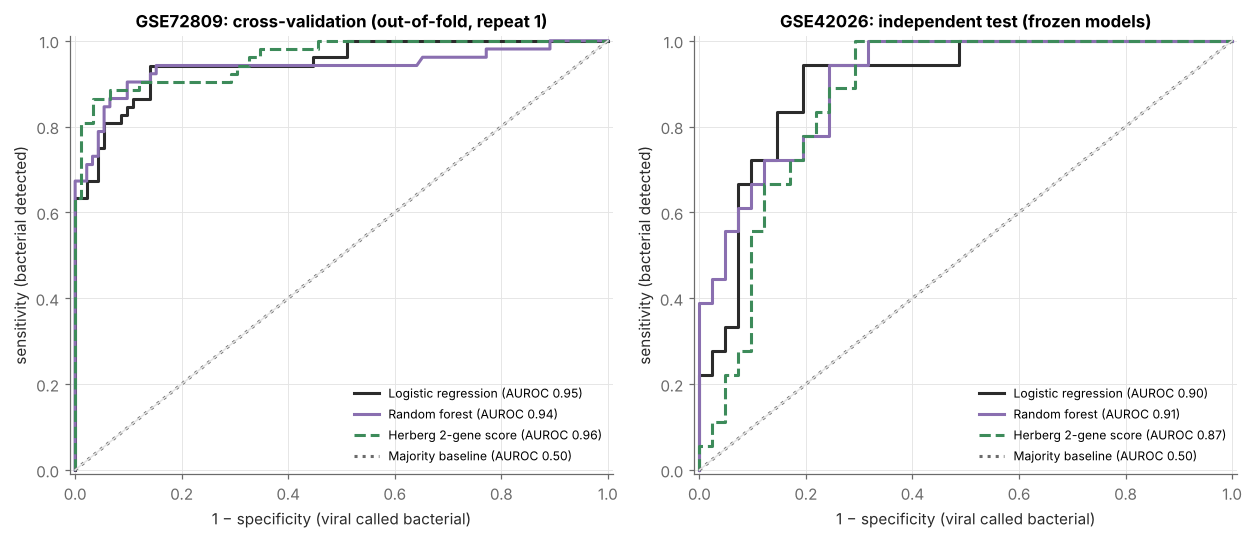

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
styles = {"Logistic regression": ("-", INK), "Random forest": ("-", "#8A6FB0"),
          "Herberg 2-gene score": ("--", "#3D8B5A"), "Majority baseline": (":", MUTED)}
for ax, (y, probs, title) in zip(axes, [(yd, oof, f"{gse_d}: cross-validation (out-of-fold, repeat 1)"),
                                        (yt, ext_prob, f"{gse_t}: independent test (frozen models)")]):
    for name, (ls, c) in styles.items():
        fpr, tpr, _ = roc_curve(y, probs[name])
        ax.plot(fpr, tpr, ls=ls, color=c, lw=2, label=f"{name} (AUROC {roc_auc_score(y, probs[name]):.2f})")
    ax.plot([0, 1], [0, 1], color=GRID, lw=1)
    ax.set(title=title, xlabel="1 − specificity (viral called bacterial)", ylabel="sensitivity (bacterial detected)",
           xlim=(-0.01, 1.01), ylim=(-0.01, 1.01))
    ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
savefig(fig, "fig10_roc")

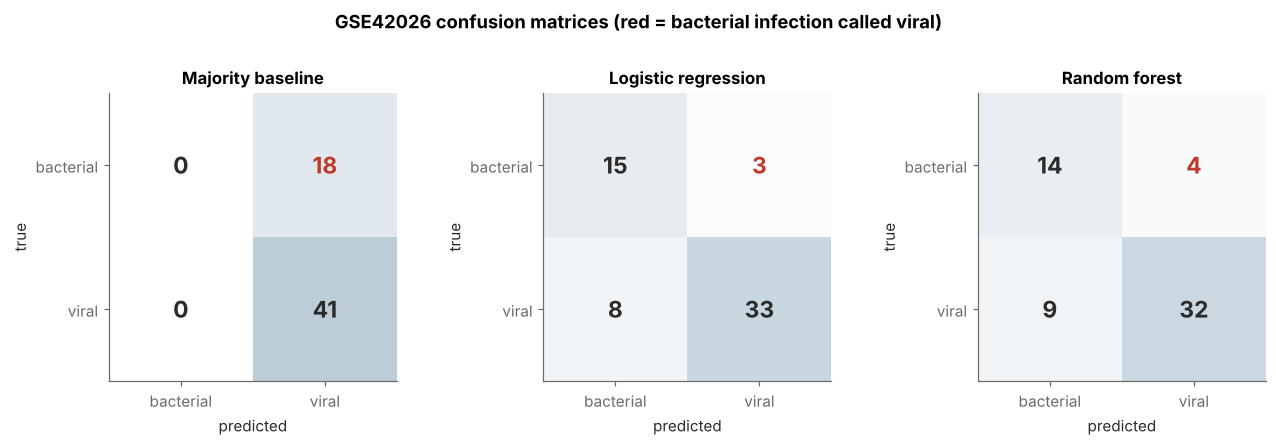

In [31]:
best_name = max(["Logistic regression", "Random forest"], key=lambda n: ext.loc[n, "balanced_accuracy"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, name in zip(axes, ["Majority baseline", "Logistic regression", "Random forest"]):
    cm = confusion_matrix(yt, (ext_prob[name] >= 0.5).astype(int), labels=[1, 0])
    ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("g", ["#FFFFFF", "#9FB8C8"]), vmin=0, vmax=len(yt))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15, fontweight="bold",
                    color="#C0392B" if (i == 0 and j == 1 and cm[i, j] > 0) else INK)
    ax.set_xticks([0, 1], ["bacterial", "viral"])
    ax.set_yticks([0, 1], ["bacterial", "viral"])
    ax.set(xlabel="predicted", ylabel="true", title=name)
    ax.grid(False)
fig.suptitle(f"{gse_t} confusion matrices (red = bacterial infection called viral)", fontweight="bold", y=1.03)
fig.tight_layout()
savefig(fig, "fig11_confusion")

### 7.2 Which children were misclassified, and which genes drive the models?

wrong_LR       wrong_RF      
                             sum count      sum count
subtype                                              
Gram-positive bacterial        3    18        4    18
H1N1/09 influenza              3    19        3    19
RSV                            5    22        6    22

,true,subtype,p_bacterial_LR,p_bacterial_RF,wrong_LR,wrong_RF
GSM1030796,Bacterial,Gram-positive bacterial,0.07,0.44,True,True
GSM1030800,Bacterial,Gram-positive bacterial,0.72,0.44,False,True
GSM1030802,Bacterial,Gram-positive bacterial,0.40,0.59,True,False
GSM1030804,Bacterial,Gram-positive bacterial,0.56,0.44,False,True
GSM1030805,Bacterial,Gram-positive bacterial,0.44,0.31,True,True
GSM1030842,Viral,H1N1/09 influenza,0.54,0.54,True,True
GSM1030850,Viral,H1N1/09 influenza,0.98,0.91,True,True
GSM1030855,Viral,H1N1/09 influenza,0.74,0.82,True,True
GSM1030860,Viral,RSV,0.53,0.56,True,True
GSM1030861,Viral,RSV,0.32,0.50,False,True


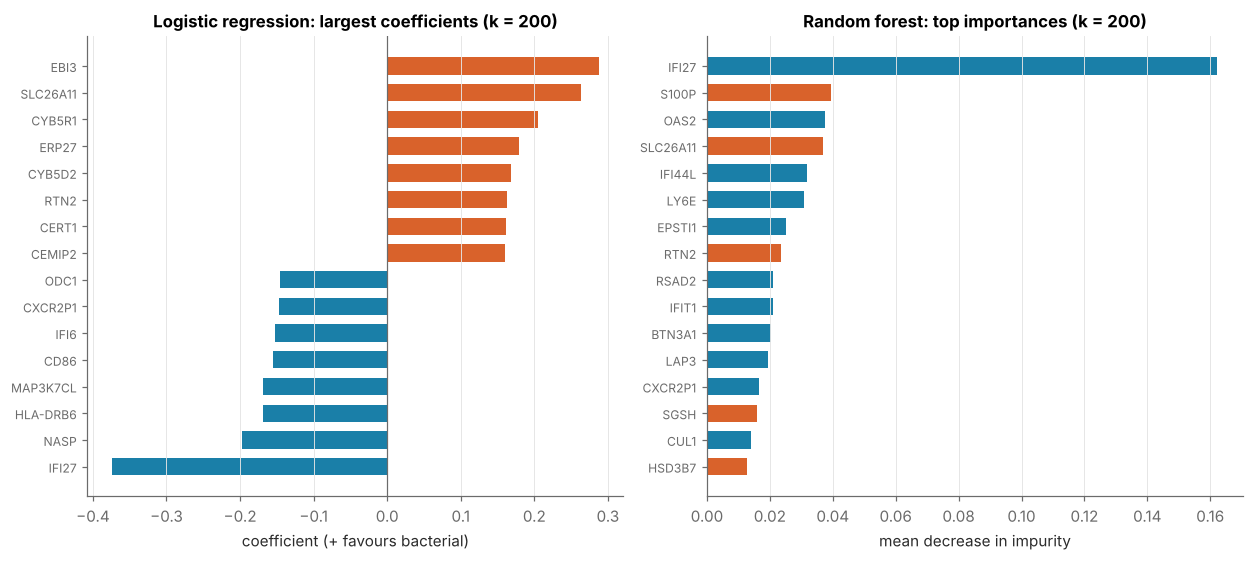

LR genes also strongly DE in Section 5: 88/200


In [32]:
meta_t = data[gse_t]["meta"].copy()
err = pd.DataFrame({"true": meta_t["group"].values, "subtype": meta_t["subtype"].values,
                    "p_bacterial_LR": ext_prob["Logistic regression"], "p_bacterial_RF": ext_prob["Random forest"]},
                   index=meta_t.index)
for k in ["LR", "RF"]:
    err[f"wrong_{k}"] = (err[f"p_bacterial_{k}"] >= 0.5) != (err["true"] == "Bacterial")
display(err.groupby("subtype")[["wrong_LR", "wrong_RF"]].agg(["sum", "count"]))
display(err[err.wrong_LR | err.wrong_RF].sort_values("true").round(2))

lr_best = final["Logistic regression"].best_estimator_
sel = np.array(shared)[lr_best.named_steps["select"].get_support()]
coef = pd.Series(lr_best.named_steps["clf"].coef_[0], index=sel).sort_values()
rf_best = final["Random forest"].best_estimator_
sel_rf = np.array(shared)[rf_best.named_steps["select"].get_support()]
imp = pd.Series(rf_best.named_steps["clf"].feature_importances_, index=sel_rf).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
c_lr = pd.concat([coef.head(8), coef.tail(8)]).drop_duplicates()
axes[0].barh(c_lr.index, c_lr.values, color=[COL["Bacterial"] if v > 0 else COL["Viral"] for v in c_lr.values], height=0.65)
axes[0].axvline(0, color=MUTED, lw=0.8)
axes[0].set(title=f"Logistic regression: largest coefficients (k = {len(sel)})", xlabel="coefficient (+ favours bacterial)")
top_imp = imp.tail(16)
axes[1].barh(top_imp.index, top_imp.values, height=0.65,
             color=[COL["Bacterial"] if de.loc[g, "log2FC"] > 0 else COL["Viral"] for g in top_imp.index])
axes[1].set(title=f"Random forest: top importances (k = {len(sel_rf)})", xlabel="mean decrease in impurity")
for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
savefig(fig, "fig12_model_genes")
print("LR genes also strongly DE in Section 5:", f"{np.isin(sel, strong.index).sum()}/{len(sel)}")

### 7.3 Sensitivity check: what if the platforms are not harmonised?
To show why within-dataset standardisation matters, the same frozen pipelines are re-trained on unstandardised log2
values and applied to the raw GSE42026 values.

In [33]:
sens_rows = []
Rd, Rt = Gd.loc[shared].T.values, Gt.loc[shared].T.values
for name in ["Logistic regression", "Random forest"]:
    m = clone(MODELS[name]).fit(Rd, yd)
    p = m.predict_proba(Rt)[:, 1]
    sens_rows.append(dict(model=name, harmonisation="none (raw log2)", **metrics(yt, p)))
    sens_rows.append(dict(model=name, harmonisation="within-dataset z-score", **metrics(yt, ext_prob[name])))
keep_t = ~Gt.columns.isin(qc_flagged[gse_t])
for name in ["Logistic regression", "Random forest"]:
    sens_rows.append(dict(model=name, harmonisation=f"z-score, {(~keep_t).sum()} QC-flagged test arrays removed",
                          **metrics(yt[keep_t], ext_prob[name][keep_t])))
sens = pd.DataFrame(sens_rows)
display(sens[["model", "harmonisation", "balanced_accuracy", "sensitivity_bacterial", "specificity_viral", "auroc"]].round(3))

,model,harmonisation,balanced_accuracy,sensitivity_bacterial,specificity_viral,auroc
0,Logistic regression,none (raw log2),0.682,0.389,0.976,0.873
1,Logistic regression,within-dataset z-score,0.819,0.833,0.805,0.901
2,Random forest,none (raw log2),0.828,0.778,0.878,0.935
3,Random forest,within-dataset z-score,0.779,0.778,0.780,0.908
4,Logistic regression,"z-score, 5 QC-flagged test arrays removed",0.797,0.800,0.795,0.892
5,Random forest,"z-score, 5 QC-flagged test arrays removed",0.785,0.800,0.769,0.906


In [34]:
summary = dict(
    counts=count_table.to_dict(orient="records"),
    n_genes_tested=int(len(de)), n_de=int(len(sig)), n_de_bact=int((sig.log2FC > 0).sum()), n_de_viral=int((sig.log2FC < 0).sum()),
    n_strong=int(len(strong)), n_strong_bact=int((strong.log2FC > 0).sum()), n_strong_viral=int((strong.log2FC < 0).sum()),
    top_bact=list(de[de.log2FC > 0].head(10).index), top_viral=list(de[de.log2FC < 0].head(10).index),
    replication_same_direction=float(same_dir.mean()), replication_same_dir_p05=float(rep.mean()),
    replication_strong=f"{int(rep_strong.sum())}/{len(strong_both)}", fc_correlation_de=float(r_sig.statistic),
    n_shared_genes=len(shared), cv_mean=cv_summary.xs("mean", axis=1, level=1).round(4).to_dict(orient="index"),
    cv_sd=cv_summary.xs("std", axis=1, level=1).round(4).to_dict(orient="index"), external=ext.drop(columns=[]).to_dict(orient="index"),
    sensitivity=sens.to_dict(orient="records"), modules=modules.to_dict(orient="records"),
    hallmark_bact=enrich[("Hallmark", "bacterial")].head(5)[["term", "FDR", "overlap"]].to_dict(orient="records"),
    hallmark_viral=enrich[("Hallmark", "viral")].head(5)[["term", "FDR", "overlap"]].to_dict(orient="records"),
    go_bact=enrich[("GO BP 2021", "bacterial")].head(8)[["term", "FDR", "overlap"]].to_dict(orient="records"),
    go_viral=enrich[("GO BP 2021", "viral")].head(8)[["term", "FDR", "overlap"]].to_dict(orient="records"),
    final_params={n: str(final[n].best_params_) for n in ["Logistic regression", "Random forest"]},
    lr_genes=list(sel), errors=err.groupby("subtype")[["wrong_LR", "wrong_RF"]].sum().to_dict(),
)
(RES / "summary.json").write_text(json.dumps(summary, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("saved results/summary.json")

saved results/summary.json


**Interpretation.**
* **Baseline.** The majority-class baseline is useless by design: it calls every child viral, so it misses all 18
  bacterial infections (balanced accuracy 0.50, AUROC 0.50).
* **Cross-validation on GSE72809.**
  * Logistic regression: balanced accuracy 0.85 ± 0.06, AUROC 0.94.
  * Random forest: balanced accuracy 0.88 ± 0.05, AUROC 0.94.
  * The training-free two-gene Herberg score does as well (balanced accuracy 0.89, AUROC 0.96), which is optimistic
    because those genes were chosen on this very dataset.
  * Tuning chose 200 genes in most folds, but no single setting won a clear majority of folds. Performance is stable;
    the exact hyper-parameters are not.
* **Independent test on GSE42026.** H1 is supported for both models: the 95% CIs exclude 0.5.

  | Model | AUROC (95% CI) | Balanced accuracy (95% CI) | Bacterial infections detected | Viral infections correctly called viral |
  |---|---|---|---|---|
  | Logistic regression | 0.90 (0.81–0.97) | 0.82 (0.70–0.92) | 15/18 | 33/41 |
  | Random forest | 0.91 (0.82–0.97) | 0.78 (0.66–0.89) | 14/18 | 32/41 |
  | Herberg score | 0.87 (0.77–0.95) | 0.80 (0.69–0.89) | 16/18 | 29/41 |

  The drop from cross-validation to the new cohort is modest (AUROC 0.94 → 0.90). The confidence intervals overlap
  heavily, so with only 18 bacterial test cases we **cannot claim that either model beats the two-gene score**.
* **Errors.**
  * Three bacterial infections were called viral by logistic regression. This is the dangerous error, and it is
    reported explicitly.
  * The false alarms were mostly RSV (5/22) and H1N1 (3/19). Children with severe viral illness can mount strong
    inflammatory responses that resemble bacterial infection.
* **Model genes.** The logistic model's most influential genes are *IFI27* (viral) and *EBI3, SLC26A11, CYB5R1*
  (bacterial), and 88 of its 200 genes are also strongly DE in Section 5. The random forest also relies most on
  *IFI27*. Both models learnt the interferon-versus-neutrophil biology rather than noise.
* **Harmonisation (Section 7.3).** Without within-dataset standardisation, logistic regression detects only 7/18
  (39%) of bacterial infections in the new cohort, because the V3 chip's different brightness pushes every child
  towards "viral". The random forest was not hurt (balanced accuracy 0.83 without vs 0.78 with standardisation), so
  the benefit depends on the model. Removing the 5 QC-flagged test arrays leaves the results essentially unchanged.
* **Reproducibility note.** Differential expression, enrichment, logistic regression and the Herberg score give
  identical numbers across library versions. Random-forest figures can move by a few points between scikit-learn
  releases, because tree-building randomness changed between versions. For example, external balanced accuracy was
  0.82 instead of 0.78 under scikit-learn 1.6. The saved outputs come from scikit-learn 1.9.1, and no conclusion
  depends on the random forest.

## 8. Conclusions

**Answer to the research question.** Children with confirmed bacterial and viral infections differ in thousands of
blood genes, organised mainly into two opposing programmes: a type I interferon programme that is higher in viral
infection, and a neutrophil and antibacterial programme that is higher in bacterial infection. These differences
replicate in an independent cohort and classify infection type there clearly better than chance. The classification
is not yet accurate enough to guide treatment.

| Objective | Conclusion |
|---|---|
| **1. Quality-check and explore the data** | Both datasets passed quality control once their different processing was handled: log2 RSN for GSE72809, floor-and-log2 for the raw-scale GSE42026. Blood and sex-gene checks behaved as expected. 10 sex mismatches and 4 low-correlation arrays were flagged, and excluding them changed no conclusion. Infection type is a secondary source of variation behind individual and erythroid biology. Sex is confounded with group in the discovery set. |
| **2. Identify differentially expressed genes and pathways** | 5,760 genes differ at FDR < 0.05 and 210 differ at least two-fold. The top genes are interferon-stimulated (*IFI44L*, *IFI27*, *RSAD2*, *IFIT1*) in viral infection and neutrophil/inflammatory (*MMP8*, *IL1R2*, *S100P*, *FAM89A*) in bacterial infection. Enrichment confirms type I interferon signalling versus neutrophil degranulation. 68% of strongly DE genes replicate in GSE42026. |
| **3. Compare a classifier with a baseline** | Both models far outperform the majority baseline in nested cross-validation (balanced accuracy 0.85–0.88 vs 0.50; AUROC 0.94). Neither beats the published two-gene score in a way our sample size can detect. |
| **4. Test on an independent dataset and explain limitations** | On the independent cohort, logistic regression reaches AUROC 0.90 (95% CI 0.81–0.97) and balanced accuracy 0.82. It detects 15/18 bacterial infections, misses 3, and misclassifies 8 of 41 viral infections, mostly RSV. Platform harmonisation was essential for the linear model. |

**Limitations**
* **Narrow test cohort.** All test bacterial infections are Gram-positive and all viral infections are H1N1/09 or
  RSV, so performance against Gram-negative bacteria, malaria or other viruses is unknown.
* **Small samples, wide uncertainty.** With 18 bacterial test cases, each confidence interval spans about ±0.1.
* **Only the clear-cut cases.** Only *definite* cases were analysed, but the children who most need such a test are
  the probable and uncertain ones (96 children in GSE72809), who were excluded by design.
* **Confounding we cannot fully remove.** Sex is unevenly split between groups, and age is not recorded, so age
  effects (for example fetal haemoglobin genes) cannot be separated from infection effects.
* **Not fully independent.** Both cohorts come from the same research network and case definitions. Within-dataset
  standardisation uses the test cohort's own (label-free) gene means, which depend slightly on its class mix.
* **Untested in Kenya.** The model has never seen Kenyan children, who differ in pathogens, co-infections such as
  malaria and HIV, nutrition and genetics. This is a research result, not a clinical tool.

**Future steps**
1. Score the probable and uncertain GSE72809 children to see how the model behaves where diagnosis is hardest.
2. Validate in an African paediatric cohort with Gram-negative, malaria and mixed infections.
3. Reduce the signature to a handful of genes measurable by RT-qPCR, and choose a decision threshold that keeps
   bacterial sensitivity at or above 95%.
4. Collect age and repeat the analysis adjusting for age and sex together.

**Code and reproducibility.** All code is in this notebook and in the group's GitHub repository (see `README.md`),
with the figures in `figures/` and every results table in `results/`.

**References**
* Herberg JA *et al.* Diagnostic test accuracy of a 2-transcript host RNA signature for discriminating bacterial vs
  viral infection in febrile children. *JAMA* 2016;316(8):835–845. (GSE72809)
* Herberg JA *et al.* Transcriptomic profiling in childhood H1N1/09 influenza reveals reduced expression of protein
  synthesis genes. *J Infect Dis* 2013;208(10):1664–1668. (GSE42026)
* Sweeney TE, Wong HR, Khatri P. Robust classification of bacterial and viral infections via integrated host gene
  expression diagnostics. *Sci Transl Med* 2016;8(346):346ra91.
* Smyth GK. Linear models and empirical Bayes methods for assessing differential expression in microarray
  experiments. *Stat Appl Genet Mol Biol* 2004;3:Article 3.
* Benjamini Y, Hochberg Y. Controlling the false discovery rate. *J R Stat Soc B* 1995;57:289–300.
* Liberzon A *et al.* The Molecular Signatures Database hallmark gene set collection. *Cell Syst* 2015;1:417–425.
* Kuleshov MV *et al.* Enrichr: a comprehensive gene set enrichment analysis web server 2016 update.
  *Nucleic Acids Res* 2016;44:W90–W97.